In [1]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.circuit import QuantumCircuit
from qiskit import transpile

qc = QuantumCircuit(1, 1)
qc.x(0)
qc.measure(0, 0)

# Build noise model
noise_model = NoiseModel()
error = depolarizing_error(0.75, 1)
noise_model.add_all_qubit_quantum_error(
    error, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# Noiseless
sim_ideal = AerSimulator()
result_ideal = sim_ideal.run(transpile(qc, sim_ideal), shots=1024).result()
print("Noiseless     :", result_ideal.get_counts())

# Noisy
sim_noisy = AerSimulator(noise_model=noise_model)
result_noisy = sim_noisy.run(transpile(qc, sim_noisy), shots=1024).result()
print("Noisy p=0.75  :", result_noisy.get_counts())

Noiseless     : {'1': 1024}
Noisy p=0.75  : {'1': 661, '0': 363}


In [2]:
sim_check = AerSimulator()
qc_t = transpile(qc, sim_check)
print("Basis gates used:", qc_t.count_ops())

Basis gates used: OrderedDict({'x': 1, 'measure': 1})


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

All imports OK ✅


In [4]:
p_true = 0.3

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")

Problem defined ✅


In [12]:
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# Build noise model
noise_model_test = NoiseModel()
error_1q = depolarizing_error(0.75, 1)
noise_model_test.add_all_qubit_quantum_error(
    error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# ── Clean baseline ──
sampler_clean = AerSampler(
    run_options={"shots": 1024}         # shots in run_options
)
iae_clean = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_clean
)
result_clean = iae_clean.estimate(problem)
print(f"p=0.00 | Estimate: {result_clean.estimation:.4f} | Queries: {result_clean.num_oracle_queries}")

# ── Noisy run ──
sampler_noisy = AerSampler(
    backend_options={"noise_model": noise_model_test},  # ✅ noise in backend_options
    run_options={"shots": 1024}                         # ✅ shots in run_options
)
iae_noisy = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_noisy
)
result_noisy = iae_noisy.estimate(problem)
print(f"p=0.75 | Estimate: {result_noisy.estimation:.4f} | Queries: {result_noisy.num_oracle_queries}")

# ── Difference check ──
diff = abs(result_clean.estimation - result_noisy.estimation)
print(f"\nDifference: {diff:.4f}")
if diff < 0.01:
    print("❌ Noise is NOT being applied!")
else:
    print("✅ Noise IS affecting the estimate!")

p=0.00 | Estimate: 0.3017 | Queries: 7168
p=0.75 | Estimate: 0.4922 | Queries: 3072

Difference: 0.1905
✅ Noise IS affecting the estimate!


In [14]:
import numpy as np
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════
# PARAMETERS — all defined here, nothing external
# ══════════════════════════════════════════════
N_REPEATS      = 30
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 40).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.6, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs}")

# ══════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════
def build_noisy_sampler(p_depol):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q = min(p_depol, 0.75)
        error_1q = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": 1024}
        )
    else:
        sampler = AerSampler(run_options={"shots": 1024})
    return sampler

# ══════════════════════════════════════════════
# SWEEP
# ══════════════════════════════════════════════
sweep_results = []
run_count     = 0

for p_noise in noise_levels:
    print(f"\n--- Noise p = {p_noise:.5f} ---")
    sampler = build_noisy_sampler(p_noise)

    for eps in epsilon_values:
        estimates = []
        queries   = []

        for repeat in range(N_REPEATS):
            run_count += 1
            try:
                iae = IterativeAmplitudeEstimation(
                    epsilon_target=eps,
                    alpha=0.05,
                    sampler=sampler,
                )
                result = iae.estimate(problem)
                estimates.append(result.estimation)
                queries.append(result.num_oracle_queries)
            except Exception as e:
                estimates.append(0.0)
                queries.append(0)

        estimates   = np.array(estimates)
        rmse        = np.sqrt(np.mean((estimates - p_true) ** 2))
        avg_queries = np.mean(queries)
        collapsed   = rmse > eps

        individual_success = [
            1 if abs(est - p_true) <= eps else 0
            for est in estimates
        ]
        success_rate = np.mean(individual_success)

        sweep_results.append({
            "epsilon"     : eps,
            "noise"       : p_noise,
            "queries"     : avg_queries,
            "rmse"        : rmse,
            "collapsed"   : collapsed,
            "success_rate": success_rate,
        })

        print(f"  [Run {run_count}/{total_runs}] "
              f"eps={eps:.6f} | "
              f"Queries={avg_queries:>8.1f} | "
              f"RMSE={rmse:.5f} | "
              f"Success={success_rate:.2f} | "
              f"{'💀 FAILED' if collapsed else '✅ OK'}")

print(f"\n✅ Sweep complete — {total_runs} total runs")

Epsilon values    : 40 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.6000
Total combinations: 1640
Total IQAE runs   : 49200

--- Noise p = 0.00000 ---


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_7100\3674684131.py:48: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [Run 30/49200] eps=0.000100 | Queries=1506406.4 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 60/49200] eps=0.000119 | Queries=1637239.5 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 90/49200] eps=0.000143 | Queries=1570065.1 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 120/49200] eps=0.000170 | Queries=1469644.8 | RMSE=0.00311 | Success=0.97 | 💀 FAILED
  [Run 150/49200] eps=0.000203 | Queries=1085098.7 | RMSE=0.00004 | Success=1.00 | ✅ OK
  [Run 180/49200] eps=0.000242 | Queries=870263.5 | RMSE=0.00003 | Success=1.00 | ✅ OK
  [Run 210/49200] eps=0.000289 | Queries=490257.1 | RMSE=0.00005 | Success=1.00 | ✅ OK
  [Run 240/49200] eps=0.000346 | Queries=466432.0 | RMSE=0.00006 | Success=1.00 | ✅ OK


KeyboardInterrupt: 

Error in callback <function _enable_matplotlib_integration.<locals>.configure_once at 0x000001CA4DC99300> (for post_run_cell), with arguments args (<ExecutionResult object at 1ca4fb893d0, execution_count=14 error_before_exec=None error_in_exec= info=<ExecutionInfo object at 1ca4fb89cd0, raw_cell="import numpy as np
from qiskit_aer.primitives impo.." transformed_cell="import numpy as np
from qiskit_aer.primitives impo.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/c%3A/documents%20for%20me/Summer-Research-2026/IQAE%20%2B%20Noise.ipynb#W5sZmlsZQ%3D%3D> result=None>,),kwargs {}:


AttributeError: module 'matplotlib' has no attribute 'backends'

In [ ]:
import numpy as np
from joblib import Parallel, delayed
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════
N_REPEATS      = 10
N_JOBS         = 18  # leave 2 threads free for system
N_shots        = 16384
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 100).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════
def build_noisy_sampler(p_depol):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q = min(p_depol, 0.75)
        error_1q = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": N_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": N_shots})
    return sampler

# ══════════════════════════════════════════════
# SINGLE COMBINATION FUNCTION — runs in parallel
# ══════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats):
    """
    Fully independent — safe to run in parallel.
    Each worker builds its own sampler.
    """
    sampler   = build_noisy_sampler(p_noise)
    estimates = []
    queries   = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target=eps,
                alpha=0.05,
                sampler=sampler,
            )
            result = iae.estimate(problem)
            estimates.append(result.estimation)
            queries.append(result.num_oracle_queries)
        except:
            estimates.append(0.0)
            queries.append(0)

    estimates    = np.array(estimates)
    rmse         = np.sqrt(np.mean((estimates - p_true) ** 2))
    avg_queries  = np.mean(queries)
    collapsed    = rmse > eps
    success_rate = np.mean([
        1 if abs(est - p_true) <= eps else 0
        for est in estimates
    ])

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "queries"     : avg_queries,
        "rmse"        : rmse,
        "collapsed"   : collapsed,
        "success_rate": success_rate,
    }

# ══════════════════════════════════════════════
# BUILD ALL COMBINATIONS
# ══════════════════════════════════════════════
combinations = [
    (p_noise, eps)
    for p_noise in noise_levels
    for eps in epsilon_values
]

print(f"\n🚀 Starting parallel sweep...")

# ══════════════════════════════════════════════
# RUN IN PARALLEL — verbose=10 shows progress
# ══════════════════════════════════════════════
sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
    delayed(run_combination)(p_noise, eps, p_true, N_REPEATS)
    for p_noise, eps in combinations
)

print(f"\n✅ Sweep complete — {len(sweep_results)} combinations done")

Epsilon values    : 100 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.4000
Total combinations: 4100
Total IQAE runs   : 123000
Running on        : 18 parallel threads

🚀 Starting parallel sweep...


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.
[Parallel(n_jobs=18)]: Done   5 tasks      | elapsed:   53.2s
[Parallel(n_jobs=18)]: Done  14 tasks      | elapsed:   59.3s
[Parallel(n_jobs=18)]: Done  25 tasks      | elapsed:  1.5min
[Parallel(n_jobs=18)]: Done  36 tasks      | elapsed:  1.5min
[Parallel(n_jobs=18)]: Done  49 tasks      | elapsed:  1.8min
[Parallel(n_jobs=18)]: Done  62 tasks      | elapsed:  2.0min
[Parallel(n_jobs=18)]: Done  77 tasks      | elapsed:  2.4min
[Parallel(n_jobs=18)]: Done  92 tasks      | elapsed:  2.4min
[Parallel(n_jobs=18)]: Done 109 tasks      | elapsed:  2.6min
[Parallel(n_jobs=18)]: Done 126 tasks      | elapsed:  2.7min
[Parallel(n_jobs=18)]: Done 145 tasks      | elapsed:  3.0min
[Parallel(n_jobs=18)]: Done 164 tasks      | elapsed:  3.3min
[Parallel(n_jobs=18)]: Done 185 tasks      | elapsed:  3.5min
[Parallel(n_jobs=18)]: Done 206 tasks      | elapsed:  3.9min
[Parallel(n_jobs=18)]: Done 229 tasks      | elapsed:  


✅ Sweep complete — 4100 combinations done


[Parallel(n_jobs=18)]: Done 4100 out of 4100 | elapsed: 37.9min finished


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import curve_fit
from joblib import Parallel, delayed
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
SHOT_VALUES    = [1024, 4096, 16384, 65536]
N_REPEATS      = 10
N_JOBS         = 18
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 100).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs} per shot count")
print(f"Shot values       : {SHOT_VALUES}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════════════════════════════════════
def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q        = min(p_depol, 0.75)
        error_1q    = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler

# ══════════════════════════════════════════════════════════════════════════════
# SINGLE COMBINATION — runs in parallel
# ══════════════════════════════════════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats, n_shots):
    """
    Fully independent — safe to run in parallel.
    Each worker builds its own sampler with its own shot count.
    """
    sampler   = build_noisy_sampler(p_noise, n_shots)
    estimates = []
    queries   = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target=eps,
                alpha=0.05,
                sampler=sampler,
            )
            result = iae.estimate(problem)
            estimates.append(result.estimation)
            queries.append(result.num_oracle_queries)
        except:
            estimates.append(0.0)
            queries.append(0)

    estimates    = np.array(estimates)
    rmse_val     = np.sqrt(np.mean((estimates - p_true) ** 2))
    avg_queries  = np.mean(queries)
    collapsed    = rmse_val > eps
    success_rate = np.mean([
        1 if abs(est - p_true) <= eps else 0
        for est in estimates
    ])

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "queries"     : avg_queries,
        "rmse"        : rmse_val,
        "collapsed"   : collapsed,
        "success_rate": success_rate,
    }

# ══════════════════════════════════════════════════════════════════════════════
# CURVE FIT MODELS  —  x-axis is log10(epsilon)
#
#   Exponential Decay : p*(ε) = a · exp( b · log10(ε) )
#                             = a · ε^b          (power law in disguise)
#     Physical read   : every decade decrease in ε multiplies tolerance by e^b
#     Asymptote       : p* → 0  as  ε → 0  (b > 0)  ✅
#
#   Power-Epsilon     : p*(ε) = a · |log10(ε)|^(-b)
#     Physical read   : tolerance decays as a power of the log-precision
#     Asymptote       : p* → 0  as  ε → 0  (b > 0)  ✅
#
#   Both are fit on  x = log10(ε)  which is negative (ε < 1),
#   so we pass  log_eps = log10(epsilon)  directly.
# ══════════════════════════════════════════════════════════════════════════════
def model_exp_decay(log_eps, a, b):
    """
    p*(ε) = a · exp( b · log10(ε) )
    Fit variable : log_eps = log10(ε)   [negative for ε < 1]
    Parameters   : a > 0  (scale),  b > 0  (decay rate)
    Note         : mathematically identical to a · ε^b
    """
    return a * np.exp(b * log_eps)

def model_power_eps(log_eps, a, b):
    """
    p*(ε) = a · |log10(ε)|^(-b)
    Fit variable : log_eps = log10(ε)   [negative for ε < 1]
    Parameters   : a > 0  (scale),  b > 0  (decay rate)
    """
    return a * (np.abs(log_eps) ** (-b))

# ══════════════════════════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot

def rmse_metric(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# BOUNDARY EXTRACTOR
#   For each unique epsilon, take the top-2 highest noise levels
#   where collapsed == False  →  these define the noise frontier
# ══════════════════════════════════════════════════════════════════════════════
def extract_boundary_points(sweep_results):
    """
    Returns arrays:
        eps_boundary  : epsilon values of boundary points
        noise_boundary: corresponding noise threshold values
    """
    eps_boundary   = []
    noise_boundary = []

    unique_epsilons = sorted(set(e["epsilon"] for e in sweep_results))

    for eps in unique_epsilons:
        # All working entries for this epsilon, sorted by noise descending
        working_noise = sorted(
            [e["noise"] for e in sweep_results
             if e["epsilon"] == eps and not e["collapsed"]],
            reverse=True
        )
        # Take top 2
        for p in working_noise[:2]:
            eps_boundary.append(eps)
            noise_boundary.append(p)

    return np.array(eps_boundary), np.array(noise_boundary)

# ══════════════════════════════════════════════════════════════════════════════
# FIT BOTH MODELS TO BOUNDARY POINTS
# ══════════════════════════════════════════════════════════════════════════════
def fit_models(eps_boundary, noise_boundary):
    """
    Fits both models on log10(epsilon) vs noise boundary points.
    Returns dict of results for each model.
    """
    log_eps = np.log10(eps_boundary)   # negative values, e.g. -4 → -1

    candidates = {
        "Exponential Decay  [a·exp(b·log(ε))]": {
            "func"  : model_exp_decay,
            "p0"    : [0.5,  1.0],
            "bounds": ([0.0,  0.001], [np.inf, np.inf]),
            "tex"   : r"$p^*(\varepsilon)=a\cdot e^{b\log_{10}\varepsilon}$",
            "color" : "#e67e22",
        },
        "Power-Epsilon       [a·|log(ε)|^(-b)]": {
            "func"  : model_power_eps,
            "p0"    : [0.5,  1.0],
            "bounds": ([0.0,  0.001], [np.inf, np.inf]),
            "tex"   : r"$p^*(\varepsilon)=a\cdot|\log_{10}\varepsilon|^{-b}$",
            "color" : "#3498db",
        },
    }

    results = {}
    for label, cfg in candidates.items():
        try:
            popt, pcov = curve_fit(
                cfg["func"],
                log_eps,
                noise_boundary,
                p0     = cfg["p0"],
                bounds = cfg["bounds"],
                maxfev = 20_000
            )
            perr   = np.sqrt(np.diag(pcov))
            y_pred = cfg["func"](log_eps, *popt)
            r2     = r_squared(noise_boundary, y_pred)
            rm     = rmse_metric(noise_boundary, y_pred)

            results[label] = {
                "popt" : popt,
                "perr" : perr,
                "r2"   : r2,
                "rmse" : rm,
                "func" : cfg["func"],
                "tex"  : cfg["tex"],
                "color": cfg["color"],
            }
        except RuntimeError as exc:
            results[label] = None
            print(f"   ⚠ Fit failed for {label}: {exc}")

    return results

# ══════════════════════════════════════════════════════════════════════════════
# PRINT RESULTS FOR ONE SHOTS COUNT
# ══════════════════════════════════════════════════════════════════════════════
def print_shot_results(n_shots, fit_results):
    print(f"\n{'═'*75}")
    print(f"  SHOTS = {n_shots}")
    print(f"{'═'*75}")
    print(f"  {'Model':<42} {'R²':>8} {'RMSE':>10} {'a':>10} {'b':>10}")
    print(f"  {'-'*72}")
    for label, res in fit_results.items():
        if res is None:
            print(f"  {label:<42} {'—':>8} {'—':>10} {'—':>10} {'—':>10}  ❌ Failed")
            continue
        a, b = res["popt"]
        print(
            f"  {label:<42} "
            f"{res['r2']:>8.4f} "
            f"{res['rmse']:>10.6f} "
            f"{a:>10.6f} "
            f"{b:>10.6f}"
        )
    print(f"{'═'*75}")

# ══════════════════════════════════════════════════════════════════════════════
# PLOT FOR ONE SHOTS COUNT
# ══════════════════════════════════════════════════════════════════════════════
def plot_shot_results(n_shots, sweep_results, fit_results, eps_boundary, noise_boundary):
    fig, ax = plt.subplots(figsize=(12, 7))

    noise_all = np.array([e["noise"] for e in sweep_results])

    # — All scatter points
    for entry in sweep_results:
        color  = '#2ecc71' if not entry["collapsed"] else '#e74c3c'
        marker = 'o'       if not entry["collapsed"] else 'X'
        ax.scatter(
            np.log10(entry["epsilon"]), entry["noise"],
            color=color, marker=marker, s=60,
            zorder=5, edgecolors='black', linewidths=0.3, alpha=0.75
        )

    # — Boundary points (top-2 per epsilon)
    ax.scatter(
        np.log10(eps_boundary), noise_boundary,
        color='white', edgecolors='gold',
        linewidths=1.8, s=80, zorder=13,
        label='Boundary points (top-2 per ε)'
    )

    # — Dense x for smooth curves
    log_eps_dense = np.linspace(
        np.log10(min(epsilon_values)),
        np.log10(max(epsilon_values)),
        600
    )

    best_label = max(
        [k for k, v in fit_results.items() if v is not None],
        key=lambda k: fit_results[k]["r2"]
    )

    for label, res in fit_results.items():
        if res is None:
            continue
        y_dense  = np.clip(res["func"](log_eps_dense, *res["popt"]), 0, noise_all.max())
        is_best  = (label == best_label)
        ax.plot(
            log_eps_dense, y_dense,
            color    = res["color"],
            linewidth= 3.0 if is_best else 1.6,
            linestyle= '--' if is_best else ':',
            alpha    = 1.0  if is_best else 0.65,
            zorder   = 12   if is_best else 9,
            label    = f"{'★ ' if is_best else ''}[R²={res['r2']:.4f} | RMSE={res['rmse']:.4f}]  {label}"
        )

    # — Safe zone under best curve
    y_best_dense = np.clip(
        fit_results[best_label]["func"](log_eps_dense, *fit_results[best_label]["popt"]),
        0, noise_all.max()
    )
    ax.fill_between(
        log_eps_dense, 0, y_best_dense,
        color='gold', alpha=0.10, zorder=4, label='Safe region (best fit)'
    )

    # — Stats annotation
    best_res = fit_results[best_label]
    a, b     = best_res["popt"]
    ae, be   = best_res["perr"]
    stats_text = (
        f"★ Best: {best_label.strip()}\n"
        f"{best_res['tex']}\n"
        f"$R^2 = {best_res['r2']:.4f}$\n"
        f"$\\mathrm{{RMSE}} = {best_res['rmse']:.4f}$\n"
        f"$a = {a:.4f} \\pm {ae:.4f}$\n"
        f"$b = {b:.4f} \\pm {be:.4f}$\n"
        f"$p^*(\\varepsilon) \\to 0$ as $\\varepsilon \\to 0$ ✅"
    )
    ax.text(
        0.02, 0.97, stats_text,
        transform=ax.transAxes, fontsize=8.5,
        verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                  edgecolor='gold', alpha=0.92)
    )

    # — Axes
    ax.set_xlim(np.log10(min(epsilon_values)), np.log10(max(epsilon_values)))
    ax.set_ylim(-0.01, noise_all.max() + 0.02)
    ax.set_xlabel(r"$\log_{10}(\varepsilon)$  — Target Precision", fontsize=13)
    ax.set_ylabel("Depolarizing Noise Level $p$",                   fontsize=13)
    ax.set_title(
        f"IQAE Noise Threshold Frontier  —  Shots = {n_shots}\n"
        f"● Working (RMSE ≤ ε)   ✕ Failed (RMSE > ε)   "
        f"Each point = avg of {N_REPEATS} runs",
        fontsize=12
    )

    base_legend = [
        mpatches.Patch(facecolor='#2ecc71', edgecolor='black', label='Working ✅  (RMSE ≤ ε)'),
        mpatches.Patch(facecolor='#e74c3c', edgecolor='black', label='Failed  💀  (RMSE > ε)'),
        mpatches.Patch(facecolor='gold',    alpha=0.3, edgecolor='none', label='Safe region (best fit)'),
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='white', markeredgecolor='gold',
                   markeredgewidth=1.8, markersize=8,
                   label='Boundary points (top-2 per ε)'),
    ]
    model_legend = [
        plt.Line2D(
            [0], [0],
            color    = res["color"],
            linewidth= 3.0 if lbl == best_label else 1.6,
            linestyle= '--' if lbl == best_label else ':',
            label    = f"{'★ ' if lbl == best_label else ''}[R²={res['r2']:.4f}]  {lbl}"
        )
        for lbl, res in fit_results.items() if res is not None
    ]
    ax.legend(
        handles        = base_legend + model_legend,
        fontsize       = 8.5,
        loc            = 'upper left',
        framealpha     = 0.90,
        title          = "★ = best model by R²",
        title_fontsize = 8,
    )
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY TABLE — printed after all shot counts are done
# ══════════════════════════════════════════════════════════════════════════════
def print_summary_table(all_shot_results):
    print(f"\n{'═'*95}")
    print(f"  FULL SUMMARY — ALL SHOT COUNTS")
    print(f"{'═'*95}")
    print(f"  {'Shots':>8}  {'Model':<42} {'R²':>8} {'RMSE':>10} {'a':>10} {'b':>10} {'Winner'}")
    print(f"  {'-'*92}")

    for n_shots, fit_results in all_shot_results.items():
        # Best model for this shot count
        valid = {k: v for k, v in fit_results.items() if v is not None}
        best  = max(valid, key=lambda k: valid[k]["r2"]) if valid else None

        for label, res in fit_results.items():
            if res is None:
                print(f"  {n_shots:>8}  {label:<42} {'—':>8} {'—':>10} {'—':>10} {'—':>10}  ❌")
                continue
            a, b  = res["popt"]
            star  = "🏆" if label == best else "  "
            print(
                f"  {n_shots:>8}  {label:<42} "
                f"{res['r2']:>8.4f} "
                f"{res['rmse']:>10.6f} "
                f"{a:>10.6f} "
                f"{b:>10.6f}  {star}"
            )
        print(f"  {'-'*92}")

    print(f"{'═'*95}")

# ══════════════════════════════════════════════════════════════════════════════
# MAIN LOOP — iterate over shot counts
# ══════════════════════════════════════════════════════════════════════════════
combinations     = [(p_noise, eps) for p_noise in noise_levels for eps in epsilon_values]
all_shot_results = {}   # stores fit_results keyed by n_shots

for n_shots in SHOT_VALUES:

    print(f"\n{'▓'*75}")
    print(f"  🚀  Running sweep  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    # ── Parallel sweep ────────────────────────────────────────────────────────
    sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
        delayed(run_combination)(p_noise, eps, p_true, N_REPEATS, n_shots)
        for p_noise, eps in combinations
    )

    print(f"\n  ✅ Sweep complete — {len(sweep_results)} combinations")

    # ── Extract boundary points ───────────────────────────────────────────────
    eps_boundary, noise_boundary = extract_boundary_points(sweep_results)
    print(f"  📍 Boundary points extracted: {len(eps_boundary)}")

    # ── Fit both models ───────────────────────────────────────────────────────
    fit_results = fit_models(eps_boundary, noise_boundary)

    # ── Store for summary ─────────────────────────────────────────────────────
    all_shot_results[n_shots] = fit_results

    # ── Per-shot output ───────────────────────────────────────────────────────
    print_shot_results(n_shots, fit_results)

    # ── Plot ──────────────────────────────────────────────────────────────────
    plot_shot_results(n_shots, sweep_results, fit_results, eps_boundary, noise_boundary)

# ══════════════════════════════════════════════════════════════════════════════
# FINAL SUMMARY — all shots together
# ══════════════════════════════════════════════════════════════════════════════
print_summary_table(all_shot_results)

Epsilon values    : 100 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.4000
Total combinations: 4100
Total IQAE runs   : 41000 per shot count
Shot values       : [1024, 4096, 16384, 65536]
Running on        : 18 parallel threads

▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  🚀  Running sweep  —  SHOTS = 1024
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.


KeyboardInterrupt: 

In [29]:
import numpy as np
from joblib import Parallel, delayed
from scipy.special import expit
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
SHOT_VALUES    = [2**10]
N_REPEATS      = 20
N_JOBS         = 18
epsilon_values = np.linspace(0.0001, 0.1, 200).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 50).tolist()

Z_95 = 1.96

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {len(epsilon_values) * len(noise_levels)}")
print(f"Total IQAE runs   : {len(epsilon_values) * len(noise_levels) * N_REPEATS} per shot count")
print(f"Shot values       : {SHOT_VALUES}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════════════════════════════════════
# WILSON SCORE INTERVAL
#
#   For k successes out of N Bernoulli trials at confidence z:
#
#        p_hat = k / N
#
#        centre = (p_hat + z²/2N) / (1 + z²/N)
#
#        half_width = z * sqrt( p_hat(1-p_hat)/N + z²/4N² )
#                     ─────────────────────────────────────
#                                 1 + z²/N
#
#   Returns (success_rate, lower_CI, upper_CI, half_width)
#   Stays bounded in [0,1] even for k=0 or k=N  ✅
# ══════════════════════════════════════════════════════════════════════════════
def wilson_score(k, n, z=Z_95):
    """
    k : number of successes
    n : total trials
    z : z-score (default 1.96 → 95% CI)
    Returns: (p_hat, lower, upper, half_width)
    """
    p_hat      = k / n
    z2n        = z ** 2 / n
    centre     = (p_hat + z2n / 2) / (1 + z2n)
    half_width = (z * np.sqrt(p_hat * (1 - p_hat) / n + z2n / 4)) / (1 + z2n)
    lower      = np.clip(centre - half_width, 0.0, 1.0)
    upper      = np.clip(centre + half_width, 0.0, 1.0)
    return float(p_hat), float(lower), float(upper), float(half_width)

# ══════════════════════════════════════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════════════════════════════════════
def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q        = min(p_depol, 0.75)
        error_1q    = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler

# ══════════════════════════════════════════════════════════════════════════════
# SINGLE COMBINATION — runs in parallel
#
#   Each repeat is a Bernoulli trial:
#       success (1) : |estimate - p_true| <= epsilon
#       failure (0) : |estimate - p_true| >  epsilon
#
#   Returns the success rate + Wilson CI for the (eps, noise) point
# ══════════════════════════════════════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats, n_shots):
    sampler  = build_noisy_sampler(p_noise, n_shots)
    outcomes = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target = eps,
                alpha          = 0.05,
                sampler        = sampler,
            )
            result  = iae.estimate(problem)
            success = 1 if abs(result.estimation - p_true) <= eps else 0
            outcomes.append(success)
        except:
            outcomes.append(0)

    k                           = sum(outcomes)
    p_hat, lower, upper, half_w = wilson_score(k, n_repeats)

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "success_rate": p_hat,
        "wilson_lower": lower,
        "wilson_upper": upper,
        "wilson_hw"   : half_w,
        "k"           : k,
        "n"           : n_repeats,
    }

# ══════════════════════════════════════════════════════════════════════════════
# MAIN SIMULATION LOOP — iterates over all shot counts
# Results stored in `all_sweep_results` for Cell 2 to consume
# ══════════════════════════════════════════════════════════════════════════════
combinations     = [(p_noise, eps) for p_noise in noise_levels for eps in epsilon_values]
all_sweep_results = {}   # { n_shots : [list of result dicts] }

for n_shots in SHOT_VALUES:

    print(f"\n{'▓'*75}")
    print(f"  🚀  Running sweep  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
        delayed(run_combination)(p_noise, eps, p_true, N_REPEATS, n_shots)
        for p_noise, eps in combinations
    )

    all_sweep_results[n_shots] = sweep_results
    print(f"\n  ✅ Sweep complete — {len(sweep_results)} combinations stored")

print(f"\n{'═'*75}")
print(f"  ✅ ALL SWEEPS COMPLETE — results stored in `all_sweep_results`")
print(f"  Keys: {list(all_sweep_results.keys())}")
print(f"{'═'*75}")

Epsilon values    : 200 | 0.000100 → 0.100000
Noise levels      : 51  | 0.0000 → 0.4000
Total combinations: 10200
Total IQAE runs   : 204000 per shot count
Shot values       : [1024]
Running on        : 18 parallel threads

▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  🚀  Running sweep  —  SHOTS = 1024
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.
[Parallel(n_jobs=18)]: Done   5 tasks      | elapsed:   13.6s
[Parallel(n_jobs=18)]: Done  14 tasks      | elapsed:   17.2s
[Parallel(n_jobs=18)]: Done  25 tasks      | elapsed:   21.6s
[Parallel(n_jobs=18)]: Done  36 tasks      | elapsed:   28.4s
[Parallel(n_jobs=18)]: Done  49 tasks      | elapsed:   32.4s
[Parallel(n_jobs=18)]: Done  62 tasks      | elapsed:   37.3s
[Parallel(n_jobs=18)]: Done  77 tasks      | elapsed:   44.1s
[Parallel(n_jobs=18)]: Done  92 tasks      | elapsed:   46.0s
[Parallel(n_jobs=18)]: Done 109 tasks      | elapsed:   49.8s
[Parallel(n_jobs=18)]: Done 126 tasks      | elapsed:   53.4s
[Parallel(n_jobs=18)]: Done 145 tasks      | elapsed:   57.4s
[Parallel(n_jobs=18)]: Done 164 tasks      | elapsed:  1.0min
[Parallel(n_jobs=18)]: Done 185 tasks      | elapsed:  1.1min
[Parallel(n_jobs=18)]: Done 206 tasks      | elapsed:  1.2min
[Parallel(n_jobs=18)]: Done 229 tasks      | elapsed:  


  ✅ Sweep complete — 10200 combinations stored

═══════════════════════════════════════════════════════════════════════════
  ✅ ALL SWEEPS COMPLETE — results stored in `all_sweep_results`
  Keys: [1024]
═══════════════════════════════════════════════════════════════════════════


[Parallel(n_jobs=18)]: Done 10200 out of 10200 | elapsed: 25.3min finished



▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📊  Analysing  —  SHOTS = 1024
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📍 Boundary points: 176 kept, 24 dropped (|ŝ - 0.5| > 0.1)
    Sawtooth:  m=2.6985  c=0.1388  B=0.4665  φ=3.0684  R²=0.7557


Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.


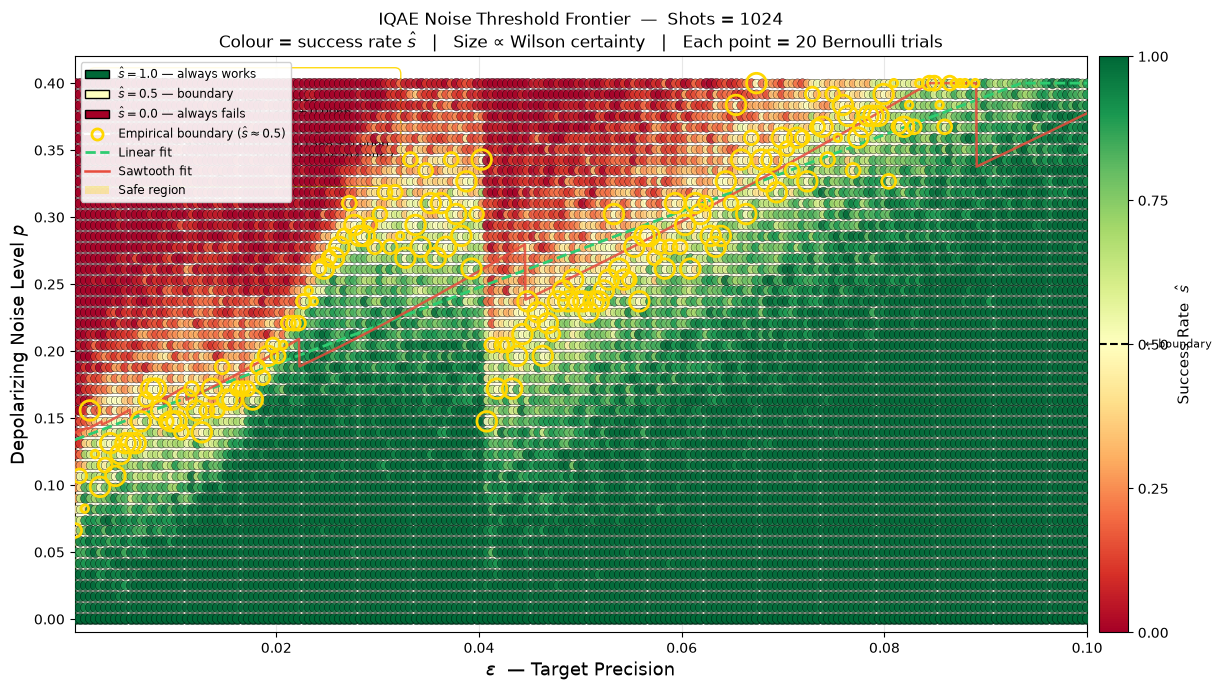

Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.


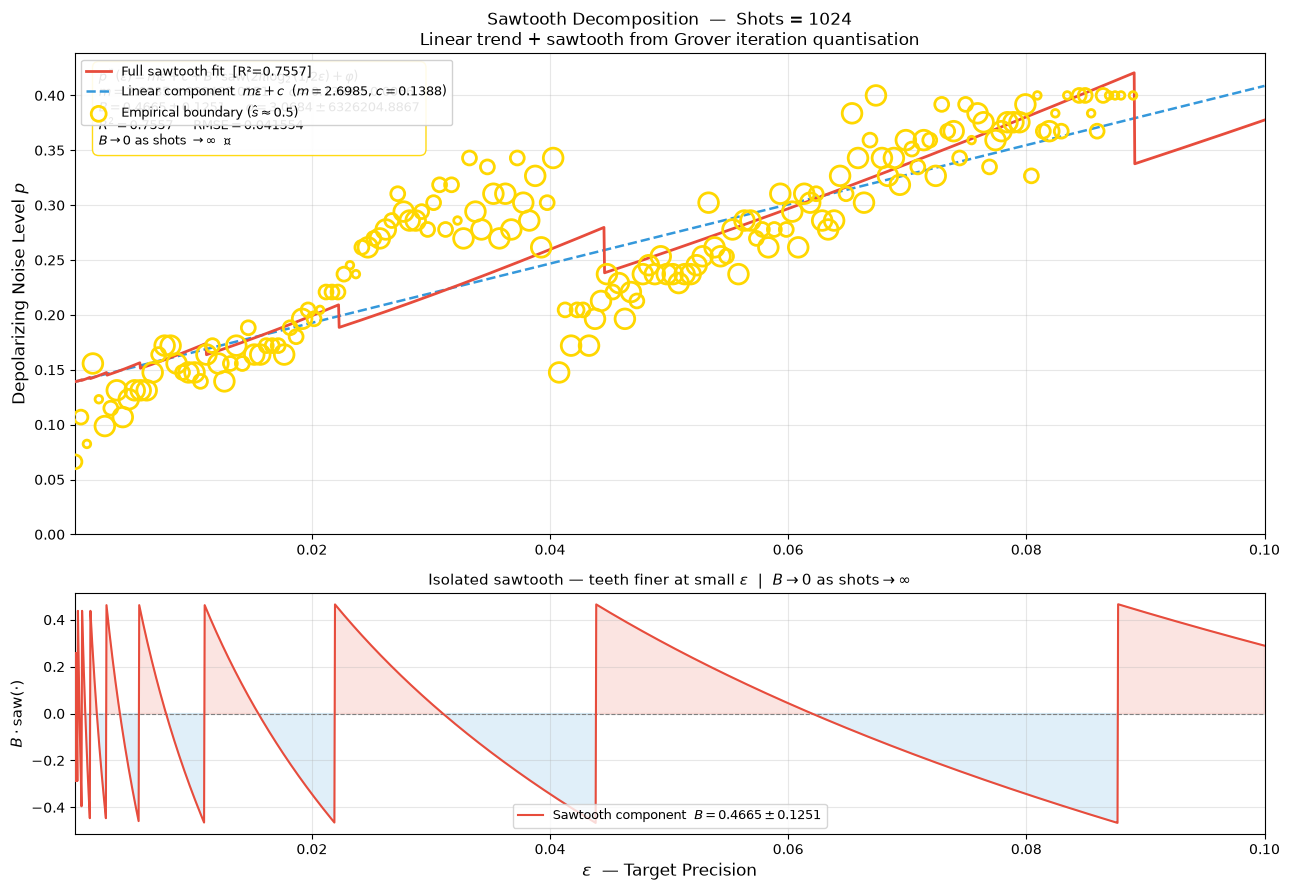


════════════════════════════════════════════════════════════════════════════════
  LINEAR FIT SUMMARY  |  p*(ε) = m·ε + c
════════════════════════════════════════════════════════════════════════════════
     Shots        R²        RMSE           m         σ_m           c         σ_c
  ----------------------------------------------------------------------------
      1024    0.7470    0.042287    2.851981    0.133857    0.133403    0.006627

════════════════════════════════════════════════════════════════════════════════
  SAWTOOTH FIT SUMMARY  |  p*(ε) = m·ε + c + B·saw(2π·log2(1/2ε)+φ)
════════════════════════════════════════════════════════════════════════════════
     Shots        R²        RMSE           m           c           B           φ  Note
  ----------------------------------------------------------------------------
      1024    0.7557    0.041554    2.698547    0.138835    0.466540      3.0684  B=0.4665
═══════════════════════════════════════════════════════════════════

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit
from scipy.signal import sawtooth as scipy_sawtooth

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
ACCEPTANCE_BAND = 0.10   # accept points where success_rate ∈ [0.40, 0.60]

# ══════════════════════════════════════════════════════════════════════════════
# EMPIRICAL BOUNDARY EXTRACTOR
#
#   For each unique epsilon:
#     1. Find the noise point whose success_rate is closest to 0.5
#     2. Only keep it if within ACCEPTANCE_BAND of 0.5
#     3. Tail points (boundary above grid ceiling) fall outside the band
#        naturally — no forced truncation needed
# ══════════════════════════════════════════════════════════════════════════════
def extract_empirical_boundary(sweep_results):
    eps_boundary   = []
    pstar_boundary = []
    srate_boundary = []

    unique_epsilons = sorted(set(e["epsilon"] for e in sweep_results))

    for eps in unique_epsilons:
        pts = [e for e in sweep_results if e["epsilon"] == eps]
        pts.sort(key=lambda x: x["noise"])

        distances = [abs(p["success_rate"] - 0.5) for p in pts]
        idx_best  = int(np.argmin(distances))
        best_pt   = pts[idx_best]

        if distances[idx_best] > ACCEPTANCE_BAND:
            continue

        eps_boundary.append(eps)
        pstar_boundary.append(best_pt["noise"])
        srate_boundary.append(best_pt["success_rate"])

    n_total   = len(unique_epsilons)
    n_kept    = len(eps_boundary)
    n_dropped = n_total - n_kept
    print(f"  📍 Boundary points: {n_kept} kept, "
          f"{n_dropped} dropped (|ŝ - 0.5| > {ACCEPTANCE_BAND})")

    return (np.array(eps_boundary),
            np.array(pstar_boundary),
            np.array(srate_boundary))

# ══════════════════════════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot

def rmse_metric(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# MODELS
# ══════════════════════════════════════════════════════════════════════════════
def linear_model(eps, m, c):
    """p*(ε) = m·ε + c"""
    return m * eps + c

def sawtooth_model(eps, m, c, B, phi):
    """
    p*(ε) = m·ε + c + B·ε · saw( 2π·log2(2ε) + φ )

    m   : linear slope
    c   : intercept
    B   : sawtooth amplitude scale  (dimensionless, → 0 as shots → ∞)
    phi : phase offset
    """
    eps_safe = np.clip(eps, 1e-10, np.inf)
    phase    = 2.0 * np.pi * np.log2(2.0 * eps_safe) + phi
    saw      = scipy_sawtooth(phase, width=1.0)    # ramp up → drop ✅
    return m * eps + c + B * eps_safe * saw        # amplitude ∝ ε  ✅

# ══════════════════════════════════════════════════════════════════════════════
# LINEAR FIT
# ══════════════════════════════════════════════════════════════════════════════
def fit_linear(eps_boundary, pstar_boundary, srate_boundary):
    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights

    try:
        popt, pcov = curve_fit(
            linear_model,
            eps_boundary,
            pstar_boundary,
            p0     = [1.0,  0.0],
            bounds = ([0.0, -np.inf], [np.inf, np.inf]),
            sigma  = fit_sigma,
            maxfev = 20_000
        )
        perr   = np.sqrt(np.diag(pcov))
        y_pred = linear_model(eps_boundary, *popt)
        return {
            "popt": popt, "perr": perr,
            "r2"  : r_squared(pstar_boundary, y_pred),
            "rmse": rmse_metric(pstar_boundary, y_pred),
        }
    except RuntimeError as exc:
        print(f"  ⚠ Linear fit failed: {exc}")
        return None

# ══════════════════════════════════════════════════════════════════════════════
# SAWTOOTH FIT
#
#   Fits p*(ε) = m·ε + c + B·saw(2π·log2(1/2ε) + φ)
#
#   Key physical constraint:
#     B(shots) → 0 as shots → ∞
#   This is verified by plotting B vs log2(shots) after all sweeps.
#   If B decays monotonically the sawtooth model is confirmed.
# ══════════════════════════════════════════════════════════════════════════════
def fit_sawtooth(eps_boundary, pstar_boundary, srate_boundary):
    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights

    # ── Seed from linear residuals ────────────────────────────────────────────
    m0        = (pstar_boundary[-1] - pstar_boundary[0]) / \
                (eps_boundary[-1]   - eps_boundary[0])
    c0        = pstar_boundary[0] - m0 * eps_boundary[0]
    residuals = pstar_boundary - (m0 * eps_boundary + c0)
    B0        = max((residuals.max() - residuals.min()) / 2.0, 1e-4)
    phi0      = 0.0

    try:
        popt, pcov = curve_fit(
            sawtooth_model,
            eps_boundary,
            pstar_boundary,
            p0     = [m0,    c0,    B0,   phi0],
            bounds = ([0.0,  -np.inf, 0.0,  -np.pi],
                      [np.inf, np.inf, np.inf,  np.pi]),
            sigma  = fit_sigma,
            maxfev = 100_000
        )
        perr   = np.sqrt(np.diag(pcov))
        y_pred = sawtooth_model(eps_boundary, *popt)
        m, c, B, phi = popt
        print(f"    Sawtooth:  m={m:.4f}  c={c:.4f}  "
              f"B={B:.4f}  φ={phi:.4f}  "
              f"R²={r_squared(pstar_boundary, y_pred):.4f}")
        return {
            "popt": popt, "perr": perr,
            "r2"  : r_squared(pstar_boundary, y_pred),
            "rmse": rmse_metric(pstar_boundary, y_pred),
        }
    except RuntimeError as exc:
        print(f"  ⚠ Sawtooth fit failed: {exc}")
        return None

# ══════════════════════════════════════════════════════════════════════════════
# PLOT — FRONTIER + BOTH FITS
# ══════════════════════════════════════════════════════════════════════════════
def plot_shot_results(n_shots, sweep_results,
                      fit_lin, fit_saw,
                      eps_boundary, pstar_boundary, srate_boundary):

    fig, ax = plt.subplots(figsize=(13, 7))

    noise_all  = np.array([e["noise"] for e in sweep_results])
    noise_ceil = noise_all.max()
    cmap       = cm.RdYlGn
    norm       = mcolors.Normalize(vmin=0.0, vmax=1.0)

    # ── Scatter ───────────────────────────────────────────────────────────────
    for entry in sweep_results:
        s     = entry["success_rate"]
        hw    = entry["wilson_hw"]
        color = cmap(norm(s))
        size  = np.clip(200 * (1.0 - 2 * hw), 20, 200)
        ax.scatter(entry["epsilon"], entry["noise"],
                   color=color, s=size, zorder=5,
                   edgecolors='black', linewidths=0.3, alpha=0.85)

    # ── Colorbar ──────────────────────────────────────────────────────────────
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.01)
    cbar.set_label("Success Rate  $\\hat{s}$", fontsize=11)
    cbar.set_ticks([0.0, 0.25, 0.5, 0.75, 1.0])
    cbar.ax.axhline(0.5, color='black', linewidth=1.5, linestyle='--')
    cbar.ax.text(1.6, 0.5, '← boundary', va='center', fontsize=8)

    # ── Boundary points ───────────────────────────────────────────────────────
    marker_sizes = 200 * (1.0 - np.abs(srate_boundary - 0.5) / ACCEPTANCE_BAND)
    marker_sizes = np.clip(marker_sizes, 30, 200)
    ax.scatter(eps_boundary, pstar_boundary,
               s=marker_sizes, facecolors='none',
               edgecolors='gold', linewidths=2.0, zorder=13,
               label=r'Empirical boundary ($\hat{s}\approx0.5$)')

    # ── Dense x-axis ──────────────────────────────────────────────────────────
    eps_dense = np.linspace(min(epsilon_values), max(epsilon_values), 2000)

    # ── Linear fit ────────────────────────────────────────────────────────────
    if fit_lin is not None:
        m, c   = fit_lin["popt"]
        y_lin  = np.clip(linear_model(eps_dense, m, c), 0, noise_ceil)
        ax.plot(eps_dense, y_lin,
                color='#2ecc71', linewidth=2.0, linestyle='--', zorder=11,
                label=f"Linear  [R²={fit_lin['r2']:.4f}]  "
                      f"$m={m:.4f}$  $c={c:.4f}$")
        ax.fill_between(eps_dense, 0, y_lin,
                        color='gold', alpha=0.08, zorder=4,
                        label='Safe region (linear)')

    # ── Sawtooth fit ──────────────────────────────────────────────────────────
    if fit_saw is not None:
        m, c, B, phi = fit_saw["popt"]
        y_saw = np.clip(sawtooth_model(eps_dense, m, c, B, phi), 0, noise_ceil)
        ax.plot(eps_dense, y_saw,
                color='#e74c3c', linewidth=1.8, linestyle='-', zorder=12,
                alpha=0.85,
                label=f"Sawtooth  [R²={fit_saw['r2']:.4f}]  "
                      f"$B={B:.4f}$  $\\varphi={phi:.4f}$")

    # ── Stats box ─────────────────────────────────────────────────────────────
    lines = ["Model Comparison:"]
    if fit_lin is not None:
        m, c   = fit_lin["popt"]
        me, ce = fit_lin["perr"]
        lines += [
            f"Linear:    $R^2={fit_lin['r2']:.4f}$  "
            f"RMSE$={fit_lin['rmse']:.4f}$",
            f"  $m={m:.4f}\\pm{me:.4f}$  "
            f"$c={c:.4f}\\pm{ce:.4f}$",
        ]
    if fit_saw is not None:
        m, c, B, phi     = fit_saw["popt"]
        me, ce, Be, phie = fit_saw["perr"]
        lines += [
            f"Sawtooth:  $R^2={fit_saw['r2']:.4f}$  "
            f"RMSE$={fit_saw['rmse']:.4f}$",
            f"  $m={m:.4f}\\pm{me:.4f}$  "
            f"$c={c:.4f}\\pm{ce:.4f}$",
            f"  $B={B:.4f}\\pm{Be:.4f}$  "
            f"$\\varphi={phi:.4f}\\pm{phie:.4f}$",
            f"  $B\\to0$ as shots$\\to\\infty$  ✅",
        ]
    ax.text(0.02, 0.97, "\n".join(lines),
            transform=ax.transAxes, fontsize=8.5,
            verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                      edgecolor='gold', alpha=0.92))

    # ── Axes + legend ─────────────────────────────────────────────────────────
    ax.set_xlim(min(epsilon_values), max(epsilon_values))
    ax.set_ylim(-0.01, noise_ceil + 0.02)
    ax.set_xlabel(r"$\varepsilon$  — Target Precision", fontsize=13)
    ax.set_ylabel("Depolarizing Noise Level $p$",       fontsize=13)
    ax.set_title(
        f"IQAE Noise Threshold Frontier  —  Shots = {n_shots}\n"
        f"Colour = success rate $\\hat{{s}}$   |   "
        f"Size ∝ Wilson certainty   |   "
        f"Each point = {N_REPEATS} Bernoulli trials",
        fontsize=12
    )
    base_legend = [
        mpatches.Patch(facecolor=cmap(1.0), edgecolor='black',
                       label='$\\hat{s}=1.0$ — always works'),
        mpatches.Patch(facecolor=cmap(0.5), edgecolor='black',
                       label='$\\hat{s}=0.5$ — boundary'),
        mpatches.Patch(facecolor=cmap(0.0), edgecolor='black',
                       label='$\\hat{s}=0.0$ — always fails'),
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='none', markeredgecolor='gold',
                   markeredgewidth=2.0, markersize=8,
                   label=r'Empirical boundary ($\hat{s}\approx0.5$)'),
        plt.Line2D([0], [0], color='#2ecc71', linewidth=2.0, linestyle='--',
                   label='Linear fit'),
        plt.Line2D([0], [0], color='#e74c3c', linewidth=1.8, linestyle='-',
                   label='Sawtooth fit'),
        mpatches.Patch(facecolor='gold', alpha=0.3, edgecolor='none',
                       label='Safe region'),
    ]
    ax.legend(handles=base_legend, fontsize=8.5,
              loc='upper left', framealpha=0.90)
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT — SAWTOOTH DECOMPOSITION (separate figure)
#
#   Top panel  : full sawtooth fit decomposed into linear + sawtooth parts
#   Bottom panel: isolated sawtooth component
#                 → visually confirms teeth get finer at small ε
#                 → B → 0 as shots increase is verified across the sweep
# ══════════════════════════════════════════════════════════════════════════════
def plot_sawtooth_decomposition(n_shots, fit_saw,
                                eps_boundary, pstar_boundary, srate_boundary):
    if fit_saw is None:
        print("  ⚠ No sawtooth fit to decompose.")
        return

    m, c, B, phi     = fit_saw["popt"]
    me, ce, Be, phie = fit_saw["perr"]

    eps_dense  = np.linspace(min(epsilon_values), max(epsilon_values), 2000)
    eps_safe   = np.clip(eps_dense, 1e-10, np.inf)
    phase      = 2.0 * np.pi * np.log2(1.0 / (2.0 * eps_safe)) + phi

    y_full     = sawtooth_model(eps_dense, m, c, B, phi)
    y_linear   = m * eps_dense + c
    y_saw_only = B * scipy_sawtooth(phase, width=1.0)

    fig, axes = plt.subplots(2, 1, figsize=(13, 9),
                              gridspec_kw={'height_ratios': [2, 1]})

    # ── Top: full decomposition ───────────────────────────────────────────────
    ax = axes[0]
    ax.plot(eps_dense, y_full,
            color='#e74c3c', linewidth=2.0, linestyle='-', zorder=10,
            label=f"Full sawtooth fit  [R²={fit_saw['r2']:.4f}]")
    ax.plot(eps_dense, y_linear,
            color='#3498db', linewidth=1.8, linestyle='--', zorder=9,
            label=f"Linear component  $m\\varepsilon+c$  "
                  f"($m={m:.4f}$, $c={c:.4f}$)")

    marker_sizes = np.clip(
        200 * (1.0 - np.abs(srate_boundary - 0.5) / ACCEPTANCE_BAND), 30, 200)
    ax.scatter(eps_boundary, pstar_boundary,
               s=marker_sizes, facecolors='none',
               edgecolors='gold', linewidths=2.0, zorder=13,
               label=r'Empirical boundary ($\hat{s}\approx0.5$)')

    stats_text = (
        f"$p^*(\\varepsilon) = m\\varepsilon + c + "
        f"B\\cdot\\mathrm{{saw}}(2\\pi\\log_2(1/2\\varepsilon)+\\varphi)$\n"
        f"$m={m:.4f}\\pm{me:.4f}$     $c={c:.4f}\\pm{ce:.4f}$\n"
        f"$B={B:.4f}\\pm{Be:.4f}$     $\\varphi={phi:.4f}\\pm{phie:.4f}$\n"
        f"$R^2={fit_saw['r2']:.4f}$     "
        f"RMSE$={fit_saw['rmse']:.6f}$\n"
        f"$B\\to 0$ as shots $\\to\\infty$  ✅"
    )
    ax.text(0.02, 0.97, stats_text,
            transform=ax.transAxes, fontsize=9,
            verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                      edgecolor='gold', alpha=0.92))

    ax.set_xlim(min(epsilon_values), max(epsilon_values))
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=12)
    ax.set_title(
        f"Sawtooth Decomposition  —  Shots = {n_shots}\n"
        "Linear trend + sawtooth from Grover iteration quantisation",
        fontsize=12)
    ax.legend(fontsize=9, loc='upper left', framealpha=0.9)
    ax.grid(True, alpha=0.3)

    # ── Bottom: isolated sawtooth ─────────────────────────────────────────────
    ax2 = axes[1]
    ax2.plot(eps_dense, y_saw_only,
             color='#e74c3c', linewidth=1.5, zorder=5,
             label=f"Sawtooth component  $B={B:.4f}\\pm{Be:.4f}$")
    ax2.axhline(0, color='grey', linewidth=0.8, linestyle='--')
    ax2.fill_between(eps_dense, 0, y_saw_only,
                     where=y_saw_only > 0,
                     color='#e74c3c', alpha=0.15)
    ax2.fill_between(eps_dense, 0, y_saw_only,
                     where=y_saw_only < 0,
                     color='#3498db', alpha=0.15)
    ax2.set_xlim(min(epsilon_values), max(epsilon_values))
    ax2.set_xlabel(r"$\varepsilon$  — Target Precision", fontsize=12)
    ax2.set_ylabel("$B\\cdot\\mathrm{saw}(\\cdot)$",     fontsize=11)
    ax2.set_title(
        "Isolated sawtooth — teeth finer at small $\\varepsilon$  |  "
        "$B\\to0$ as shots$\\to\\infty$",
        fontsize=11)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT — B vs SHOTS
#
#   The central verification plot.
#   If the sawtooth model is correct:
#     B(shots) → 0  monotonically as shots increases  ✅
#
#   Fit B = B0 · shots^(-γ)  in log-log space to extract the decay rate.
#   If γ > 0 and the fit is good, the model is self-consistent.
# ══════════════════════════════════════════════════════════════════════════════
def plot_B_vs_shots(all_saw_results):

    valid   = {s: r for s, r in all_saw_results.items() if r is not None}
    if len(valid) < 2:
        print("  ⚠ Need at least 2 shot counts to plot B vs shots.")
        return

    shots   = np.array(sorted(valid.keys()))
    B_arr   = np.array([valid[s]["popt"][2] for s in shots])
    Be_arr  = np.array([valid[s]["perr"][2] for s in shots])
    m_arr   = np.array([valid[s]["popt"][0] for s in shots])
    me_arr  = np.array([valid[s]["perr"][0] for s in shots])
    log2s   = np.log2(shots)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ── Left: B vs log2(shots) ────────────────────────────────────────────────
    ax = axes[0]
    ax.errorbar(log2s, B_arr, yerr=Be_arr,
                fmt='o', color='#e74c3c', ecolor='gold',
                elinewidth=1.5, capsize=4, markersize=8,
                markeredgecolor='black', markeredgewidth=0.8,
                zorder=5, label="Sawtooth amplitude $B$")

    # Fit B = B0 · 2^(-γ · log2(shots)) = B0 · shots^(-γ)
    if len(shots) >= 3:
        try:
            def power_decay(log2s, log_B0, gamma):
                return log_B0 - gamma * log2s

            # Fit in log space
            log_B     = np.log(np.clip(B_arr, 1e-10, np.inf))
            log_Be    = Be_arr / np.clip(B_arr, 1e-10, np.inf)
            popt, pcov = curve_fit(power_decay, log2s, log_B,
                                   sigma=log_Be, maxfev=10_000)
            perr      = np.sqrt(np.diag(pcov))
            log_B0, gamma = popt
            B0        = np.exp(log_B0)
            B0e       = B0 * perr[0]
            gammae    = perr[1]

            x_dense   = np.linspace(log2s.min(), log2s.max(), 300)
            y_dense   = B0 * 2.0 ** (-gamma * x_dense)
            y_pred    = B0 * shots ** (-gamma)
            r2_B      = r_squared(B_arr, y_pred)

            ax.plot(x_dense, y_dense,
                    color='#c0392b', linewidth=2.0, linestyle='--', zorder=4,
                    label=(f"$B=B_0\\cdot\\mathrm{{shots}}^{{-\\gamma}}$\n"
                           f"$B_0={B0:.4f}\\pm{B0e:.4f}$\n"
                           f"$\\gamma={gamma:.4f}\\pm{gammae:.4f}$\n"
                           f"$R^2={r2_B:.4f}$"))
            print(f"  B decay fit:  B0={B0:.4f}  γ={gamma:.4f}  R²={r2_B:.4f}")
        except RuntimeError:
            print("  ⚠ B decay fit failed")

    ax.axhline(0, color='grey', linewidth=0.8, linestyle=':')
    ax.set_xlabel("$\\log_2(\\text{shots})$",    fontsize=12)
    ax.set_ylabel("Sawtooth Amplitude $B$",       fontsize=12)
    ax.set_title("$B\\to0$ as shots$\\to\\infty$\n"
                 "Sawtooth washes out — linear frontier recovered",
                 fontsize=11)
    ax.legend(fontsize=9, framealpha=0.9)
    ax.grid(True, alpha=0.3)

    # ── Right: m vs log2(shots) ───────────────────────────────────────────────
    ax2 = axes[1]
    ax2.errorbar(log2s, m_arr, yerr=me_arr,
                 fmt='o', color='#2ecc71', ecolor='gold',
                 elinewidth=1.5, capsize=4, markersize=8,
                 markeredgecolor='black', markeredgewidth=0.8,
                 zorder=5, label="Linear slope $m$")
    ax2.set_xlabel("$\\log_2(\\text{shots})$", fontsize=12)
    ax2.set_ylabel("Linear Slope $m$",          fontsize=12)
    ax2.set_title("Slope $m$ vs shots\n"
                  "(frontier shifts down as shots increase)",
                  fontsize=11)
    ax2.legend(fontsize=9, framealpha=0.9)
    ax2.grid(True, alpha=0.3)

    plt.suptitle(
        "Sawtooth Model Parameter Evolution vs Shot Count\n"
        r"$p^*(\varepsilon,\mathrm{shots})="
        r"m\varepsilon+c+B(\mathrm{shots})"
        r"\cdot\mathrm{saw}(2\pi\log_2(1/2\varepsilon)+\varphi)$"
        "\n"
        r"$B\to0$ as shots$\to\infty$  ✅  linear frontier recovered",
        fontsize=12
    )
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY TABLES
# ══════════════════════════════════════════════════════════════════════════════
def print_summary_table(all_fit_results, all_saw_results):
    print(f"\n{'═'*80}")
    print(f"  LINEAR FIT SUMMARY  |  p*(ε) = m·ε + c")
    print(f"{'═'*80}")
    print(f"  {'Shots':>8}  {'R²':>8}  {'RMSE':>10}  "
          f"{'m':>10}  {'σ_m':>10}  {'c':>10}  {'σ_c':>10}")
    print(f"  {'-'*76}")
    for n_shots, res in all_fit_results.items():
        if res is None:
            print(f"  {n_shots:>8}  {'—':>8}  {'—':>10}  "
                  f"{'—':>10}  {'—':>10}  {'—':>10}  {'—':>10}  ❌")
            continue
        m, c   = res["popt"]
        me, ce = res["perr"]
        print(f"  {n_shots:>8}  {res['r2']:>8.4f}  {res['rmse']:>10.6f}  "
              f"{m:>10.6f}  {me:>10.6f}  {c:>10.6f}  {ce:>10.6f}")

    print(f"\n{'═'*80}")
    print(f"  SAWTOOTH FIT SUMMARY  |  p*(ε) = m·ε + c + B·saw(2π·log2(1/2ε)+φ)")
    print(f"{'═'*80}")
    print(f"  {'Shots':>8}  {'R²':>8}  {'RMSE':>10}  "
          f"{'m':>10}  {'c':>10}  {'B':>10}  {'φ':>10}  Note")
    print(f"  {'-'*76}")
    for n_shots, res in all_saw_results.items():
        if res is None:
            print(f"  {n_shots:>8}  {'—':>8}  {'—':>10}  "
                  f"{'—':>10}  {'—':>10}  {'—':>10}  {'—':>10}  ❌")
            continue
        m, c, B, phi = res["popt"]
        note = "B≈0 ✅" if B < 0.005 else f"B={B:.4f}"
        print(f"  {n_shots:>8}  {res['r2']:>8.4f}  {res['rmse']:>10.6f}  "
              f"{m:>10.6f}  {c:>10.6f}  {B:>10.6f}  {phi:>10.4f}  {note}")
    print(f"{'═'*80}")

# ══════════════════════════════════════════════════════════════════════════════
# ANALYSIS LOOP — consumes `all_sweep_results` from Cell 1
# ══════════════════════════════════════════════════════════════════════════════
all_fit_results = {}   # linear fits
all_saw_results = {}   # sawtooth fits

for n_shots, sweep_results in all_sweep_results.items():

    print(f"\n{'▓'*75}")
    print(f"  📊  Analysing  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    eps_boundary, pstar_boundary, srate_boundary = \
        extract_empirical_boundary(sweep_results)

    # ── Fits ──────────────────────────────────────────────────────────────────
    fit_lin = fit_linear  (eps_boundary, pstar_boundary, srate_boundary)
    fit_saw = fit_sawtooth(eps_boundary, pstar_boundary, srate_boundary)

    all_fit_results[n_shots] = fit_lin
    all_saw_results[n_shots] = fit_saw

    # ── Per-shot plots ────────────────────────────────────────────────────────
    plot_shot_results(n_shots, sweep_results,
                      fit_lin, fit_saw,
                      eps_boundary, pstar_boundary, srate_boundary)
    plot_sawtooth_decomposition(n_shots, fit_saw,
                                eps_boundary, pstar_boundary, srate_boundary)

# ── Final outputs ─────────────────────────────────────────────────────────────
print_summary_table(all_fit_results, all_saw_results)
plot_B_vs_shots(all_saw_results)



▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📊  Analysing  —  SHOTS = 1024
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📍 Boundary points: 139 kept, 61 dropped (|ŝ - 0.5| > 0.05)
    Linear:  m=2.8500  c=0.1334  R²=0.6716  RMSE=0.044643
    Seed:  m=3.6373  c=0.0658  B=0.1114  K=4.1000
    Full:  m=3.6579  c=0.1198  B=1.0846  K=3.9176  R²=0.8913  RMSE=0.025678


Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.


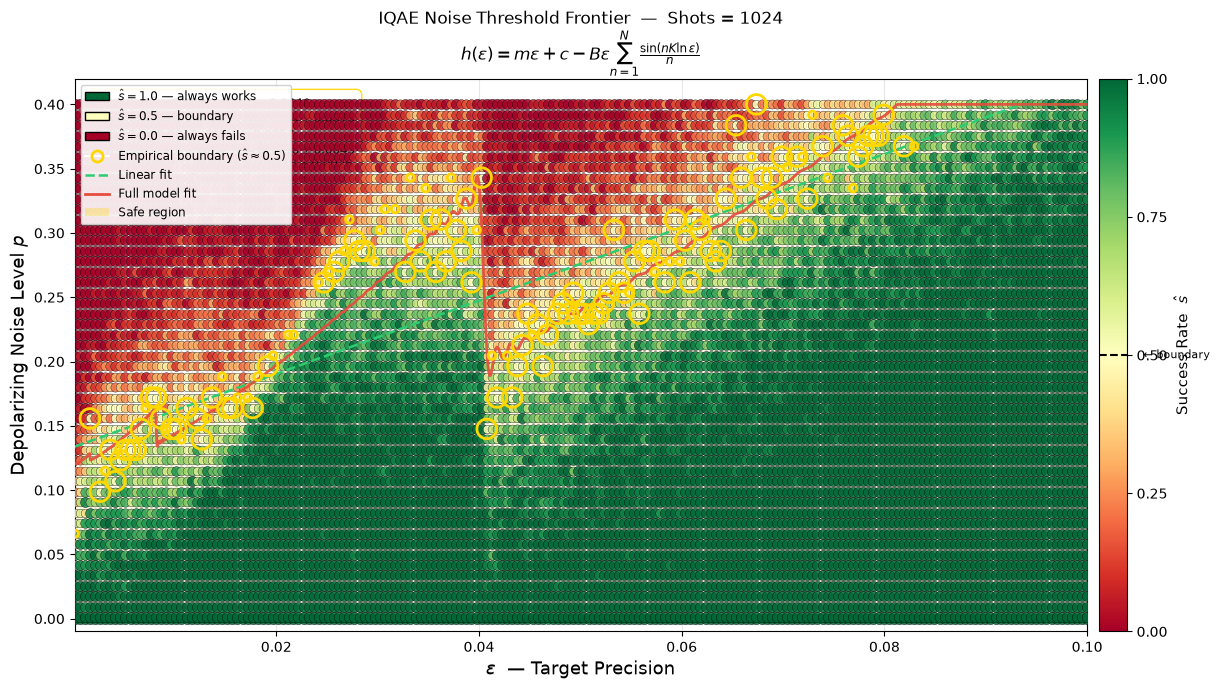

Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.


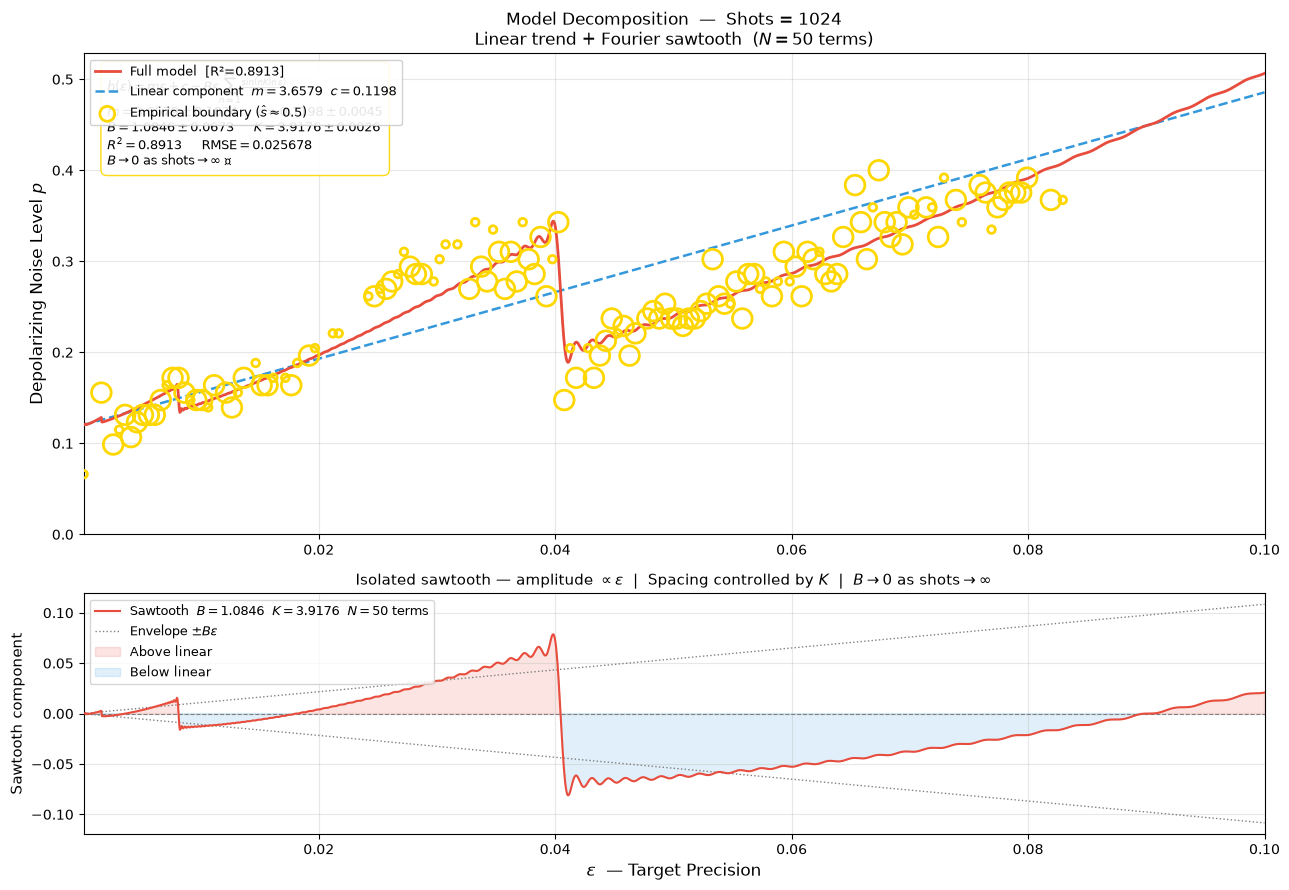


  Shots = 1024  |  Residual stats:
    mean = +0.005379   std = 0.044317   max = +0.114854   min = -0.102036


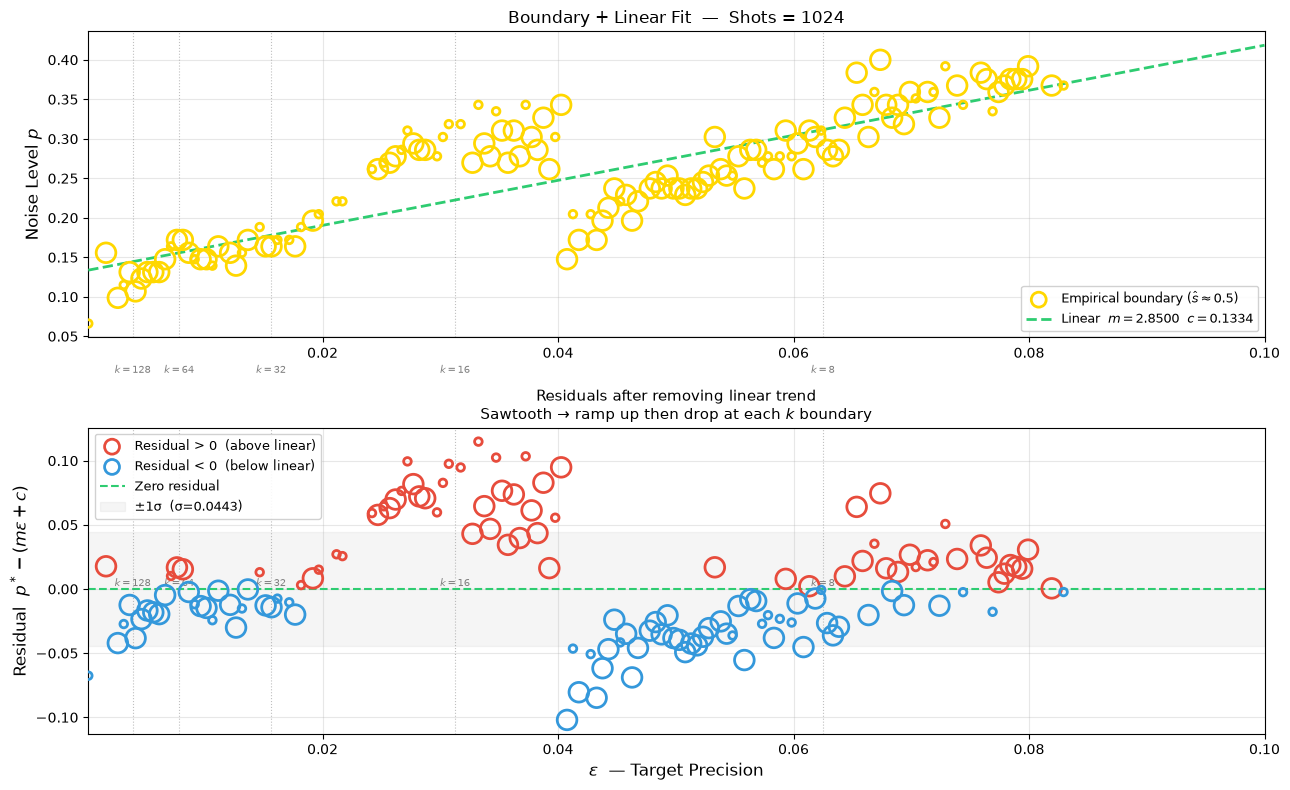


════════════════════════════════════════════════════════════════════════════════
  LINEAR FIT  |  p*(ε) = m·ε + c
════════════════════════════════════════════════════════════════════════════════
     Shots        R²        RMSE           m         σ_m           c         σ_c
  ----------------------------------------------------------------------------
      1024    0.6716    0.044643    2.850018    0.151512    0.133433    0.007490

════════════════════════════════════════════════════════════════════════════════
  FULL MODEL  |  h(ε) = m·ε + c - B·ε·Σsin(nKε)/n  [N=50]
════════════════════════════════════════════════════════════════════════════════
     Shots        R²        RMSE           m           c           B           K  Note
  ----------------------------------------------------------------------------
      1024    0.8913    0.025678    3.657908    0.119823    1.084643      3.9176  sawtooth active
══════════════════════════════════════════════════════════════════════════════

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
ACCEPTANCE_BAND = 0.05   # accept points where success_rate ∈ [0.40, 0.60]
N_TERMS         = 50     # Fourier truncation — higher = sharper sawtooth drops

# ══════════════════════════════════════════════════════════════════════════════
# EMPIRICAL BOUNDARY EXTRACTOR
#
#   For each unique epsilon:
#     1. Find the noise point whose success_rate is closest to 0.5
#     2. Only keep it if within ACCEPTANCE_BAND of 0.5
#     3. Tail points naturally excluded — no forced truncation
# ══════════════════════════════════════════════════════════════════════════════
def extract_empirical_boundary(sweep_results):
    eps_boundary   = []
    pstar_boundary = []
    srate_boundary = []

    unique_epsilons = sorted(set(e["epsilon"] for e in sweep_results))

    for eps in unique_epsilons:
        pts = [e for e in sweep_results if e["epsilon"] == eps]
        pts.sort(key=lambda x: x["noise"])

        distances = [abs(p["success_rate"] - 0.5) for p in pts]
        idx_best  = int(np.argmin(distances))
        best_pt   = pts[idx_best]

        if distances[idx_best] > ACCEPTANCE_BAND:
            continue

        eps_boundary.append(eps)
        pstar_boundary.append(best_pt["noise"])
        srate_boundary.append(best_pt["success_rate"])

    n_total   = len(unique_epsilons)
    n_kept    = len(eps_boundary)
    n_dropped = n_total - n_kept
    print(f"  📍 Boundary points: {n_kept} kept, "
          f"{n_dropped} dropped (|ŝ - 0.5| > {ACCEPTANCE_BAND})")

    return (np.array(eps_boundary),
            np.array(pstar_boundary),
            np.array(srate_boundary))

# ══════════════════════════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot

def rmse_metric(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# MODELS
#
#   Linear baseline:
#     g(ε) = m·ε + c
#
#   Fourier sawtooth modulation:
#     f(ε) = -B·ε · Σ sin(n·K·ε) / n     n = 1..N
#
#   Full model:
#     h(ε) = g(ε) + f(ε)
#          = m·ε + c - B·ε · Σ sin(n·K·ε) / n
#
#   Parameters:
#     m : linear slope
#     c : intercept
#     B : sawtooth amplitude scale → 0 as shots → ∞  ✅
#     K : frequency — controls tooth spacing
#
#   Key properties:
#     - Amplitude ∝ ε  → larger drops at larger ε     ✅
#     - B → 0 recovers pure linear                    ✅
#     - K fitted freely — no hardcoded Grover spacing  ✅
#     - N_TERMS controls sharpness of drops            ✅
# ══════════════════════════════════════════════════════════════════════════════
def linear_model(eps, m, c):
    """g(ε) = m·ε + c"""
    return m * eps + c

def sawtooth_series(eps, K, N=N_TERMS):
    """
    f(ε) = -Σ sin(n·K·ln(ε)) / n   for n = 1..N
    Log argument gives logarithmically spaced teeth.
    """
    eps    = np.asarray(eps, dtype=float)
    eps    = np.clip(eps, 1e-10, np.inf)   # guard against log(0)
    result = np.zeros_like(eps)
    for n in range(1, N + 1):
        result -= np.sin(n * K * np.log(eps)) / n
    return result

def full_model(eps, m, c, B, K):
    """
    h(ε) = m·ε + c + B·ε · sawtooth_series(ε, K)
         = m·ε + c - B·ε · Σ sin(n·K·ln ε) / n
    """
    return m * eps + c + B * eps * sawtooth_series(eps, K)

# ══════════════════════════════════════════════════════════════════════════════
# LINEAR FIT
# ══════════════════════════════════════════════════════════════════════════════
def fit_linear(eps_boundary, pstar_boundary, srate_boundary):
    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights

    try:
        popt, pcov = curve_fit(
            linear_model,
            eps_boundary,
            pstar_boundary,
            p0     = [1.0,  0.0],
            bounds = ([0.0, -np.inf], [np.inf, np.inf]),
            sigma  = fit_sigma,
            maxfev = 20_000
        )
        perr   = np.sqrt(np.diag(pcov))
        y_pred = linear_model(eps_boundary, *popt)
        r2     = r_squared(pstar_boundary, y_pred)
        rm     = rmse_metric(pstar_boundary, y_pred)

        print(f"    Linear:  m={popt[0]:.4f}  c={popt[1]:.4f}  "
              f"R²={r2:.4f}  RMSE={rm:.6f}")
        return {
            "popt": popt, "perr": perr,
            "r2"  : r2,   "rmse": rm,
        }
    except RuntimeError as exc:
        print(f"  ⚠ Linear fit failed: {exc}")
        return None

# ══════════════════════════════════════════════════════════════════════════════
# FULL MODEL FIT
# ══════════════════════════════════════════════════════════════════════════════
def fit_full_model(eps_boundary, pstar_boundary, srate_boundary):
    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights

    # ── Seed from linear residuals ────────────────────────────────────────────
    m0        = (pstar_boundary[-1] - pstar_boundary[0]) / \
                (eps_boundary[-1]   - eps_boundary[0])
    c0        = pstar_boundary[0] - m0 * eps_boundary[0]
    residuals = pstar_boundary - (m0 * eps_boundary + c0)
    B0        = max((residuals.max() - residuals.min()) / 2.0, 1e-4)
    K0        = 4.1

    print(f"    Seed:  m={m0:.4f}  c={c0:.4f}  B={B0:.4f}  K={K0:.4f}")

    try:
        popt, pcov = curve_fit(
            full_model,
            eps_boundary,
            pstar_boundary,
            p0     = [m0,    c0,    B0,    K0   ],
            bounds = ([0.0,  -np.inf, 0.0,  0.0 ],
                      [np.inf, np.inf, np.inf, np.inf]),
            sigma  = fit_sigma,
            maxfev = 200_000
        )
        perr       = np.sqrt(np.diag(pcov))
        y_pred     = full_model(eps_boundary, *popt)
        m, c, B, K = popt
        r2         = r_squared(pstar_boundary, y_pred)
        rm         = rmse_metric(pstar_boundary, y_pred)

        print(f"    Full:  m={m:.4f}  c={c:.4f}  "
              f"B={B:.4f}  K={K:.4f}  "
              f"R²={r2:.4f}  RMSE={rm:.6f}")
        return {
            "popt": popt, "perr": perr,
            "r2"  : r2,   "rmse": rm,
        }
    except RuntimeError as exc:
        print(f"  ⚠ Full model fit failed: {exc}")
        return None

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 1 — FRONTIER + BOTH FITS
# ══════════════════════════════════════════════════════════════════════════════
def plot_frontier(n_shots, sweep_results,
                  fit_lin, fit_full,
                  eps_boundary, pstar_boundary, srate_boundary):

    fig, ax    = plt.subplots(figsize=(13, 7))
    noise_all  = np.array([e["noise"] for e in sweep_results])
    noise_ceil = noise_all.max()
    cmap       = cm.RdYlGn
    norm       = mcolors.Normalize(vmin=0.0, vmax=1.0)

    # ── Scatter ───────────────────────────────────────────────────────────────
    for entry in sweep_results:
        s     = entry["success_rate"]
        hw    = entry["wilson_hw"]
        color = cmap(norm(s))
        size  = np.clip(200 * (1.0 - 2 * hw), 20, 200)
        ax.scatter(entry["epsilon"], entry["noise"],
                   color=color, s=size, zorder=5,
                   edgecolors='black', linewidths=0.3, alpha=0.85)

    # ── Colorbar ──────────────────────────────────────────────────────────────
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.01)
    cbar.set_label("Success Rate  $\\hat{s}$", fontsize=11)
    cbar.set_ticks([0.0, 0.25, 0.5, 0.75, 1.0])
    cbar.ax.axhline(0.5, color='black', linewidth=1.5, linestyle='--')
    cbar.ax.text(1.6, 0.5, '← boundary', va='center', fontsize=8)

    # ── Boundary points ───────────────────────────────────────────────────────
    marker_sizes = np.clip(
        200 * (1.0 - np.abs(srate_boundary - 0.5) / ACCEPTANCE_BAND), 30, 200)
    ax.scatter(eps_boundary, pstar_boundary,
               s=marker_sizes, facecolors='none',
               edgecolors='gold', linewidths=2.0, zorder=13,
               label=r'Empirical boundary ($\hat{s}\approx0.5$)')

    eps_dense = np.linspace(min(epsilon_values), max(epsilon_values), 2000)

    # ── Linear fit ────────────────────────────────────────────────────────────
    if fit_lin is not None:
        m, c  = fit_lin["popt"]
        y_lin = np.clip(linear_model(eps_dense, m, c), 0, noise_ceil)
        ax.plot(eps_dense, y_lin,
                color='#2ecc71', linewidth=1.8, linestyle='--', zorder=10,
                label=f"Linear  [R²={fit_lin['r2']:.4f}]  "
                      f"$m={m:.4f}$  $c={c:.4f}$")
        ax.fill_between(eps_dense, 0, y_lin,
                        color='gold', alpha=0.08, zorder=4,
                        label='Safe region (linear)')

    # ── Full model fit ────────────────────────────────────────────────────────
    if fit_full is not None:
        m, c, B, K = fit_full["popt"]
        y_full     = np.clip(full_model(eps_dense, m, c, B, K), 0, noise_ceil)
        ax.plot(eps_dense, y_full,
                color='#e74c3c', linewidth=2.0, linestyle='-',
                zorder=12, alpha=0.9,
                label=f"Full model  [R²={fit_full['r2']:.4f}]  "
                      f"$B={B:.4f}$  $K={K:.4f}$")

    # ── Stats box ─────────────────────────────────────────────────────────────
    lines = []
    if fit_lin is not None:
        m, c   = fit_lin["popt"]
        me, ce = fit_lin["perr"]
        lines += [
            f"Linear:  $R^2={fit_lin['r2']:.4f}$  "
            f"RMSE$={fit_lin['rmse']:.4f}$",
            f"  $m={m:.4f}\\pm{me:.4f}$   "
            f"$c={c:.4f}\\pm{ce:.4f}$",
        ]
    if fit_full is not None:
        m, c, B, K     = fit_full["popt"]
        me, ce, Be, Ke = fit_full["perr"]
        lines += [
            f"Full:  $R^2={fit_full['r2']:.4f}$  "
            f"RMSE$={fit_full['rmse']:.4f}$",
            f"  $m={m:.4f}\\pm{me:.4f}$   "
            f"$c={c:.4f}\\pm{ce:.4f}$",
            f"  $B={B:.4f}\\pm{Be:.4f}$   "
            f"$K={K:.4f}\\pm{Ke:.4f}$",
            f"  $N={N_TERMS}$ terms   "
            f"$B\\to0$ as shots$\\to\\infty$ ✅",
        ]
    ax.text(0.02, 0.97, "\n".join(lines),
            transform=ax.transAxes, fontsize=8.5,
            verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                      edgecolor='gold', alpha=0.92))

    # ── Axes + legend ─────────────────────────────────────────────────────────
    ax.set_xlim(min(epsilon_values), max(epsilon_values))
    ax.set_ylim(-0.01, noise_ceil + 0.02)
    ax.set_xlabel(r"$\varepsilon$  — Target Precision", fontsize=13)
    ax.set_ylabel("Depolarizing Noise Level $p$",       fontsize=13)
    ax.set_title(
        f"IQAE Noise Threshold Frontier  —  Shots = {n_shots}\n"
        r"$h(\varepsilon)=m\varepsilon+c"
        r"-B\varepsilon\sum_{n=1}^{N}\frac{\sin(nK\ln\varepsilon)}{n}$",
        fontsize=12)

    base_legend = [
        mpatches.Patch(facecolor=cmap(1.0), edgecolor='black',
                       label='$\\hat{s}=1.0$ — always works'),
        mpatches.Patch(facecolor=cmap(0.5), edgecolor='black',
                       label='$\\hat{s}=0.5$ — boundary'),
        mpatches.Patch(facecolor=cmap(0.0), edgecolor='black',
                       label='$\\hat{s}=0.0$ — always fails'),
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='none', markeredgecolor='gold',
                   markeredgewidth=2.0, markersize=8,
                   label=r'Empirical boundary ($\hat{s}\approx0.5$)'),
        plt.Line2D([0], [0], color='#2ecc71', linewidth=1.8, linestyle='--',
                   label='Linear fit'),
        plt.Line2D([0], [0], color='#e74c3c', linewidth=2.0, linestyle='-',
                   label='Full model fit'),
        mpatches.Patch(facecolor='gold', alpha=0.3, edgecolor='none',
                       label='Safe region'),
    ]
    ax.legend(handles=base_legend, fontsize=8.5,
              loc='upper left', framealpha=0.90)
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 2 — DECOMPOSITION
#   Top    : full model + linear component + boundary points
#   Bottom : isolated sawtooth component
# ══════════════════════════════════════════════════════════════════════════════
def plot_decomposition(n_shots, fit_full,
                       eps_boundary, pstar_boundary, srate_boundary):
    if fit_full is None:
        print("  ⚠ No full model fit to decompose.")
        return

    m, c, B, K     = fit_full["popt"]
    me, ce, Be, Ke = fit_full["perr"]

    eps_dense  = np.linspace(min(epsilon_values), max(epsilon_values), 2000)
    y_full     = full_model(eps_dense, m, c, B, K)
    y_linear   = linear_model(eps_dense, m, c)
    y_saw_only = B * eps_dense * sawtooth_series(eps_dense, K)

    fig, axes = plt.subplots(2, 1, figsize=(13, 9),
                              gridspec_kw={'height_ratios': [2, 1]})

    # ── Top: full decomposition ───────────────────────────────────────────────
    ax = axes[0]
    ax.plot(eps_dense, y_full,
            color='#e74c3c', linewidth=2.0, zorder=10,
            label=f"Full model  [R²={fit_full['r2']:.4f}]")
    ax.plot(eps_dense, y_linear,
            color='#3498db', linewidth=1.8, linestyle='--', zorder=9,
            label=f"Linear component  $m={m:.4f}$  $c={c:.4f}$")

    marker_sizes = np.clip(
        200 * (1.0 - np.abs(srate_boundary - 0.5) / ACCEPTANCE_BAND), 30, 200)
    ax.scatter(eps_boundary, pstar_boundary,
               s=marker_sizes, facecolors='none',
               edgecolors='gold', linewidths=2.0, zorder=13,
               label=r'Empirical boundary ($\hat{s}\approx0.5$)')

    stats_text = (
        f"$h(\\varepsilon)=m\\varepsilon+c"
        f"-B\\varepsilon\\sum_{{n=1}}^{{{N_TERMS}}}"
        f"\\frac{{\\sin(nK\\ln\\varepsilon)}}{{n}}$\n"
        f"$m={m:.4f}\\pm{me:.4f}$     "
        f"$c={c:.4f}\\pm{ce:.4f}$\n"
        f"$B={B:.4f}\\pm{Be:.4f}$     "
        f"$K={K:.4f}\\pm{Ke:.4f}$\n"
        f"$R^2={fit_full['r2']:.4f}$     "
        f"RMSE$={fit_full['rmse']:.6f}$\n"
        f"$B\\to0$ as shots$\\to\\infty$ ✅"
    )
    ax.text(0.02, 0.97, stats_text,
            transform=ax.transAxes, fontsize=9,
            verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                      edgecolor='gold', alpha=0.92))

    ax.set_xlim(min(epsilon_values), max(epsilon_values))
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=12)
    ax.set_title(
        f"Model Decomposition  —  Shots = {n_shots}\n"
        f"Linear trend + Fourier sawtooth  ($N={N_TERMS}$ terms)",
        fontsize=12)
    ax.legend(fontsize=9, loc='upper left', framealpha=0.9)
    ax.grid(True, alpha=0.3)

    # ── Bottom: isolated sawtooth ─────────────────────────────────────────────
    ax2 = axes[1]
    ax2.plot(eps_dense, y_saw_only,
             color='#e74c3c', linewidth=1.5, zorder=5,
             label=f"Sawtooth  $B={B:.4f}$  $K={K:.4f}$  "
                   f"$N={N_TERMS}$ terms")
    ax2.plot(eps_dense,  B * eps_dense,
             color='grey', linewidth=1.0, linestyle=':',
             label="Envelope $\\pm B\\varepsilon$")
    ax2.plot(eps_dense, -B * eps_dense,
             color='grey', linewidth=1.0, linestyle=':')
    ax2.fill_between(eps_dense, 0, y_saw_only,
                     where=y_saw_only >= 0,
                     color='#e74c3c', alpha=0.15,
                     label='Above linear')
    ax2.fill_between(eps_dense, 0, y_saw_only,
                     where=y_saw_only <  0,
                     color='#3498db', alpha=0.15,
                     label='Below linear')
    ax2.axhline(0, color='grey', linewidth=0.8, linestyle='--')
    ax2.set_xlim(min(epsilon_values), max(epsilon_values))
    ax2.set_xlabel(r"$\varepsilon$  — Target Precision", fontsize=12)
    ax2.set_ylabel("Sawtooth component",               fontsize=11)
    ax2.set_title(
        "Isolated sawtooth — amplitude $\\propto\\varepsilon$  |  "
        "Spacing controlled by $K$  |  "
        "$B\\to0$ as shots$\\to\\infty$",
        fontsize=11)
    ax2.legend(fontsize=9, loc='upper left')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 3 — RESIDUALS
#   Subtracts linear fit from boundary points.
#   Sawtooth → ramp up then drop pattern visible.
# ══════════════════════════════════════════════════════════════════════════════
def plot_residuals(n_shots, fit_lin,
                   eps_boundary, pstar_boundary, srate_boundary):
    if fit_lin is None:
        print("  ⚠ No linear fit for residuals.")
        return

    m, c      = fit_lin["popt"]
    residuals = pstar_boundary - linear_model(eps_boundary, m, c)

    fig, axes = plt.subplots(2, 1, figsize=(13, 8),
                              gridspec_kw={'height_ratios': [1, 1]})

    eps_dense = np.linspace(min(epsilon_values), max(epsilon_values), 1000)
    y_lin     = linear_model(eps_dense, m, c)

    marker_sizes = np.clip(
        200 * (1.0 - np.abs(srate_boundary - 0.5) / ACCEPTANCE_BAND), 30, 200)

    # ── Top: boundary + linear ────────────────────────────────────────────────
    ax1 = axes[0]
    ax1.scatter(eps_boundary, pstar_boundary,
                s=marker_sizes, facecolors='none',
                edgecolors='gold', linewidths=2.0, zorder=5,
                label=r'Empirical boundary ($\hat{s}\approx0.5$)')
    ax1.plot(eps_dense, y_lin,
             color='#2ecc71', linewidth=2.0, linestyle='--', zorder=4,
             label=f"Linear  $m={m:.4f}$  $c={c:.4f}$")

    for j in range(0, 8):
        eps_drop = 1.0 / (2.0 * 2.0 ** j)
        if min(epsilon_values) <= eps_drop <= max(epsilon_values):
            ax1.axvline(eps_drop, color='grey', linewidth=0.8,
                        linestyle=':', alpha=0.5)
            ax1.text(eps_drop, 0, f"$k={2**j}$",
                     fontsize=7, ha='center', color='grey', va='bottom')

    ax1.set_xlim(min(epsilon_values), max(epsilon_values))
    ax1.set_ylabel("Noise Level $p$",  fontsize=12)
    ax1.set_title(f"Boundary + Linear Fit  —  Shots = {n_shots}", fontsize=12)
    ax1.legend(fontsize=9, framealpha=0.9)
    ax1.grid(True, alpha=0.3)

    # ── Bottom: residuals ─────────────────────────────────────────────────────
    ax2 = axes[1]
    pos_mask = residuals >= 0
    neg_mask = residuals <  0

    ax2.scatter(eps_boundary[pos_mask], residuals[pos_mask],
                s=marker_sizes[pos_mask], facecolors='none',
                edgecolors='#e74c3c', linewidths=2.0, zorder=5,
                label='Residual > 0  (above linear)')
    ax2.scatter(eps_boundary[neg_mask], residuals[neg_mask],
                s=marker_sizes[neg_mask], facecolors='none',
                edgecolors='#3498db', linewidths=2.0, zorder=5,
                label='Residual < 0  (below linear)')
    ax2.axhline(0, color='#2ecc71', linewidth=1.5,
                linestyle='--', label='Zero residual')

    std_res = np.std(residuals)
    ax2.axhspan(-std_res, std_res, color='grey', alpha=0.08,
                label=f'±1σ  (σ={std_res:.4f})')

    for j in range(0, 8):
        eps_drop = 1.0 / (2.0 * 2.0 ** j)
        if min(epsilon_values) <= eps_drop <= max(epsilon_values):
            ax2.axvline(eps_drop, color='grey', linewidth=0.8,
                        linestyle=':', alpha=0.5)
            ax2.text(eps_drop, 0, f"$k={2**j}$",
                     fontsize=7, ha='center', color='grey', va='bottom')

    ax2.set_xlim(min(epsilon_values), max(epsilon_values))
    ax2.set_xlabel(r"$\varepsilon$  — Target Precision", fontsize=12)
    ax2.set_ylabel("Residual  $p^*-(m\\varepsilon+c)$", fontsize=12)
    ax2.set_title(
        "Residuals after removing linear trend\n"
        "Sawtooth → ramp up then drop at each $k$ boundary",
        fontsize=11)
    ax2.legend(fontsize=9, framealpha=0.9, loc='upper left')
    ax2.grid(True, alpha=0.3)

    print(f"\n  Shots = {n_shots}  |  Residual stats:")
    print(f"    mean = {np.mean(residuals):+.6f}   "
          f"std = {np.std(residuals):.6f}   "
          f"max = {np.max(residuals):+.6f}   "
          f"min = {np.min(residuals):+.6f}")

    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 4 — B vs SHOTS
#   Verifies B → 0 as shots → ∞
#   Fits B = B0 · shots^(-γ) in log space
# ══════════════════════════════════════════════════════════════════════════════
def plot_B_vs_shots(all_full_results):
    valid  = {s: r for s, r in all_full_results.items() if r is not None}
    if len(valid) < 2:
        print("  ⚠ Need at least 2 shot counts to plot B vs shots.")
        return

    shots  = np.array(sorted(valid.keys()))
    B_arr  = np.array([valid[s]["popt"][2] for s in shots])
    Be_arr = np.array([valid[s]["perr"][2] for s in shots])
    K_arr  = np.array([valid[s]["popt"][3] for s in shots])
    Ke_arr = np.array([valid[s]["perr"][3] for s in shots])
    m_arr  = np.array([valid[s]["popt"][0] for s in shots])
    me_arr = np.array([valid[s]["perr"][0] for s in shots])
    log2s  = np.log2(shots)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # ── B vs log2(shots) ──────────────────────────────────────────────────────
    ax = axes[0]
    ax.errorbar(log2s, B_arr, yerr=Be_arr,
                fmt='o', color='#e74c3c', ecolor='gold',
                elinewidth=1.5, capsize=4, markersize=8,
                markeredgecolor='black', markeredgewidth=0.8,
                zorder=5, label="Amplitude $B$")

    if len(shots) >= 3:
        try:
            def power_decay(log2s, log_B0, gamma):
                return log_B0 - gamma * log2s

            log_B      = np.log(np.clip(B_arr,  1e-10, np.inf))
            log_Be     = Be_arr / np.clip(B_arr, 1e-10, np.inf)
            popt, pcov = curve_fit(power_decay, log2s, log_B,
                                   sigma=log_Be, maxfev=10_000)
            perr       = np.sqrt(np.diag(pcov))
            B0         = np.exp(popt[0])
            gamma      = popt[1]
            B0e        = B0 * perr[0]
            gammae     = perr[1]
            x_dense    = np.linspace(log2s.min(), log2s.max(), 300)
            y_dense    = B0 * 2.0 ** (-gamma * x_dense)
            y_pred     = B0 * shots ** (-gamma)
            r2_B       = r_squared(B_arr, y_pred)

            ax.plot(x_dense, y_dense,
                    color='#c0392b', linewidth=2.0, linestyle='--', zorder=4,
                    label=(f"$B=B_0\\cdot\\mathrm{{shots}}^{{-\\gamma}}$\n"
                           f"$B_0={B0:.4f}\\pm{B0e:.4f}$\n"
                           f"$\\gamma={gamma:.4f}\\pm{gammae:.4f}$\n"
                           f"$R^2={r2_B:.4f}$"))
        except RuntimeError:
            print("  ⚠ B decay fit failed")

    ax.axhline(0, color='grey', linewidth=0.8, linestyle=':')
    ax.set_xlabel("$\\log_2(\\text{shots})$",    fontsize=12)
    ax.set_ylabel("Sawtooth Amplitude $B$",       fontsize=12)
    ax.set_title("$B\\to0$ as shots$\\to\\infty$\n"
                 "Sawtooth washes out → linear recovered",
                 fontsize=11)
    ax.legend(fontsize=9, framealpha=0.9)
    ax.grid(True, alpha=0.3)

    # ── K vs log2(shots) ──────────────────────────────────────────────────────
    axes[1].errorbar(log2s, K_arr, yerr=Ke_arr,
                     fmt='o', color='#9b59b6', ecolor='gold',
                     elinewidth=1.5, capsize=4, markersize=8,
                     markeredgecolor='black', markeredgewidth=0.8,
                     label="Frequency $K$")
    axes[1].set_xlabel("$\\log_2(\\text{shots})$", fontsize=12)
    axes[1].set_ylabel("Frequency $K$",             fontsize=12)
    axes[1].set_title("$K$ vs shots\n"
                      "(tooth spacing stability)",  fontsize=11)
    axes[1].legend(fontsize=9, framealpha=0.9)
    axes[1].grid(True, alpha=0.3)

    # ── m vs log2(shots) ──────────────────────────────────────────────────────
    axes[2].errorbar(log2s, m_arr, yerr=me_arr,
                     fmt='o', color='#2ecc71', ecolor='gold',
                     elinewidth=1.5, capsize=4, markersize=8,
                     markeredgecolor='black', markeredgewidth=0.8,
                     label="Linear slope $m$")
    axes[2].set_xlabel("$\\log_2(\\text{shots})$", fontsize=12)
    axes[2].set_ylabel("Linear Slope $m$",          fontsize=12)
    axes[2].set_title("$m$ vs shots\n"
                      "(frontier shifts down)",     fontsize=11)
    axes[2].legend(fontsize=9, framealpha=0.9)
    axes[2].grid(True, alpha=0.3)

    plt.suptitle(
        "Model Parameters vs Shot Count\n"
        r"$h(\varepsilon)=m\varepsilon+c"
        r"-B\varepsilon\sum_{n=1}^{N}\frac{\sin(nK\varepsilon)}{n}$"
        "\n"
        r"$B\to0$ as shots$\to\infty$ ✅  linear frontier recovered",
        fontsize=12)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY TABLES
# ══════════════════════════════════════════════════════════════════════════════
def print_summary_table(all_fit_results, all_full_results):
    print(f"\n{'═'*80}")
    print(f"  LINEAR FIT  |  p*(ε) = m·ε + c")
    print(f"{'═'*80}")
    print(f"  {'Shots':>8}  {'R²':>8}  {'RMSE':>10}  "
          f"{'m':>10}  {'σ_m':>10}  {'c':>10}  {'σ_c':>10}")
    print(f"  {'-'*76}")
    for n_shots, res in all_fit_results.items():
        if res is None:
            print(f"  {n_shots:>8}  {'—':>8}  {'—':>10}  "
                  f"{'—':>10}  {'—':>10}  {'—':>10}  {'—':>10}")
            continue
        m, c   = res["popt"]
        me, ce = res["perr"]
        print(f"  {n_shots:>8}  {res['r2']:>8.4f}  {res['rmse']:>10.6f}  "
              f"{m:>10.6f}  {me:>10.6f}  {c:>10.6f}  {ce:>10.6f}")

    print(f"\n{'═'*80}")
    print(f"  FULL MODEL  |  h(ε) = m·ε + c - B·ε·Σsin(nKε)/n  "
          f"[N={N_TERMS}]")
    print(f"{'═'*80}")
    print(f"  {'Shots':>8}  {'R²':>8}  {'RMSE':>10}  "
          f"{'m':>10}  {'c':>10}  {'B':>10}  {'K':>10}  Note")
    print(f"  {'-'*76}")
    for n_shots, res in all_full_results.items():
        if res is None:
            print(f"  {n_shots:>8}  {'—':>8}  {'—':>10}  "
                  f"{'—':>10}  {'—':>10}  {'—':>10}  {'—':>10}")
            continue
        m, c, B, K = res["popt"]
        note = "B≈0 ✅ linear" if B < 0.01 else "sawtooth active"
        print(f"  {n_shots:>8}  {res['r2']:>8.4f}  {res['rmse']:>10.6f}  "
              f"{m:>10.6f}  {c:>10.6f}  {B:>10.6f}  {K:>10.4f}  {note}")
    print(f"{'═'*80}")

# ══════════════════════════════════════════════════════════════════════════════
# ANALYSIS LOOP — consumes `all_sweep_results` from Cell 1
# ══════════════════════════════════════════════════════════════════════════════
all_fit_results  = {}   # linear fits
all_full_results = {}   # full model fits

for n_shots, sweep_results in all_sweep_results.items():

    print(f"\n{'▓'*75}")
    print(f"  📊  Analysing  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    eps_boundary, pstar_boundary, srate_boundary = \
        extract_empirical_boundary(sweep_results)

    # ── Fits ──────────────────────────────────────────────────────────────────
    fit_lin  = fit_linear(eps_boundary, pstar_boundary, srate_boundary)
    fit_full = fit_full_model(eps_boundary, pstar_boundary, srate_boundary)

    all_fit_results[n_shots]  = fit_lin
    all_full_results[n_shots] = fit_full

    # ── Per-shot plots ────────────────────────────────────────────────────────
    plot_frontier(n_shots, sweep_results,
                  fit_lin, fit_full,
                  eps_boundary, pstar_boundary, srate_boundary)

    plot_decomposition(n_shots, fit_full,
                       eps_boundary, pstar_boundary, srate_boundary)

    plot_residuals(n_shots, fit_lin,
                   eps_boundary, pstar_boundary, srate_boundary)

# ── Final outputs ─────────────────────────────────────────────────────────────
print_summary_table(all_fit_results, all_full_results)
plot_B_vs_shots(all_full_results)